# Phase 4 – Feature Analysis and Comparison
**Gujarati Accent Classifier**

This notebook explores the Phase 3 MFCC, delta and delta-delta features: which vary between the available accent groups, which overlap heavily, and whether the apparent differences are driven by **silence, background noise or the original audio format (M4A vs OGG)**.

**Read this first**
- Exploratory and descriptive only. It is **not** evidence that the accents can be reliably distinguished.
- There is **one speaker per accent**. Accent, speaker, microphone/app, original format and the words used are completely mixed together. No test of statistical significance is run, because recordings from one speaker are not independent samples of an accent.
- Nothing from Phases 1-3 is changed. All 28 recordings are kept (including the 11 flagged ones). No noise reduction, clipping repair or normalisation is applied.
- No PCA, feature selection or classification is done here (Phase 5 onwards). "Candidate" features below are only things worth a closer look; no feature is discarded.
- Accent and format categories are **discovered from the data**. When genuine Surti recordings are added and Phases 1-3 are re-run, they are included automatically.

## 0. Setup
Imports, paths, and a fingerprint (SHA-256) of every Phase 1-3 output so that, at the end, we can prove nothing was modified.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import config as cfg
import audio_analysis as aa
import mfcc_features as mf
import feature_analysis as fa
import feature_plots as fp

fa.FA_DIR.mkdir(parents=True, exist_ok=True)
fa.FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 120)

HASHES_BEFORE = fa.snapshot_hashes()
print("Fingerprinted", len(HASHES_BEFORE), "existing Phase 1-3 files.")

FIGS = []                                   # every figure name we create (checked at the end)
def save(fig, name):
    FIGS.append(name); fp.save(fig, name)

Fingerprinted 128 existing Phase 1-3 files.


## A. Load and inspect the data
We load four things: the Phase 1 metadata, the Phase 2 quality metrics, the Phase 3 recording-level features, and (later) the frame-level NPZ files. The **list of acoustic feature columns comes from `mfcc_feature_columns.json`**, not from guessing. Metadata, quality indicators and acoustic features are kept in separate groups. Accent, speaker ID, recording ID and quality flags are never treated as acoustic inputs.

In [2]:
data = fa.load_inputs()
for name, ok, detail in data["checks"]:
    print("PASS" if ok else "FAIL", "-", name, ("(" + detail + ")") if detail and not ok else "")
assert all(ok for _, ok, _ in data["checks"]), "Input consistency checks failed"

T, F = data["table"], data["features"]
ACCENTS, FORMATS = data["accents"], data["formats"]
COLORS, MARKERS = fa.accent_colors(ACCENTS), fa.format_markers(FORMATS)

print()
print("Accents found in the data :", ACCENTS)
print("Configured but with no recordings:", data["configured_missing"] or "none")
print("Original formats found    :", FORMATS)
print("Recordings:", len(T), "| acoustic feature columns:", len(F))

PASS - Recording IDs: Phase 1 metadata == Phase 3 features 
PASS - Recording IDs: Phase 2 metrics cover every recording 
PASS - Recording IDs are unique 
PASS - 'accent' agrees between Phase 1 and Phase 3 
PASS - 'speaker_id' agrees between Phase 1 and Phase 3 
PASS - 'region' agrees between Phase 1 and Phase 3 
PASS - 'original_format' agrees between Phase 1 and Phase 3 
PASS - Phase 3 feature columns match mfcc_feature_columns.json exactly (names and order) 
PASS - Phase 3 feature columns match the schema generated by mfcc_features.py 
PASS - Extraction parameters in schema equal mfcc_features.PARAMS 
PASS - No metadata column is listed as an acoustic feature 
PASS - No NaN/inf in the acoustic feature matrix 
PASS - A frame-level NPZ exists for every recording 
PASS - 'flag_clipping' agrees between Phase 2 and Phase 3 
PASS - 'flag_level_inconsistent' agrees between Phase 2 and Phase 3 
PASS - Phase 2 quality metrics present for every recording 

Accents found in the data : ['Ahmedab

In [3]:
counts = pd.DataFrame({"accent": fa.configured_accents() + [a for a in ACCENTS if a not in fa.configured_accents()]})
counts["recordings"] = counts["accent"].map(T.groupby("accent").size()).fillna(0).astype(int)
counts["original_format"] = counts["accent"].map(T.groupby("accent")["original_format"].agg(lambda s: ", ".join(sorted(set(s))))).fillna("-")
counts["speakers"] = counts["accent"].map(T.groupby("accent")["speaker_id"].nunique()).fillna(0).astype(int)
counts["note"] = counts["recordings"].map(lambda n: "pending future collection - not included" if n == 0 else "")
display(counts)

groups = pd.DataFrame({"role": ["Metadata (identifiers, never model input)", "Quality indicators (Phase 2, analysed separately)", "Acoustic features (Phase 3)"],
                       "columns": [len(data["schema"]["metadata"]), len(fa.QUALITY_COLUMNS), len(F)],
                       "examples": [", ".join(data["schema"]["metadata"][:4]) + ", ...", ", ".join(fa.QUALITY_COLUMNS[:4]) + ", ...", ", ".join(F[:3]) + ", ..."]})
display(groups)

,accent,recordings,original_format,speakers,note
0,Ahmedabad,7,M4A,1,
1,Kutchi,7,M4A,1,
2,Mehsani,7,OGG,1,
3,Kathiyawadi,7,OGG,1,
4,Surti,0,-,0,pending future collection - not included


,role,columns,examples
0,"Metadata (identifiers, never model input)",11,"recording_id, speaker_id, accent, region, ..."
1,"Quality indicators (Phase 2, analysed separately)",7,"speech_ratio, noise_floor_dbfs, duration_s, cl..."
2,Acoustic features (Phase 3),78,"mfcc_01_mean, mfcc_01_std, mfcc_02_mean, ..."


## B. Descriptive feature analysis
For every feature (13 coefficients x MFCC / delta / delta-delta x mean / std = 78) we compute, **per accent**, the mean, standard deviation, minimum, median and maximum across that accent's recordings. Each figure below shows **every individual recording as a dot** (shape = original format) on top of a box that summarises the middle half of the recordings, so the group summary never hides the individual values. Saved: `accent_feature_statistics.csv`.

In [4]:
stats_all = fa.accent_feature_statistics(T, F, ACCENTS)
stats_all.to_csv(fa.FA_DIR / "accent_feature_statistics.csv", index=False)
print("saved accent_feature_statistics.csv", stats_all.shape)
disp = stats_all[(stats_all.feature_group == "mfcc") & (stats_all.statistic == "mean")]
display(disp.pivot(index="coefficient", columns="accent", values="mean").reindex(columns=ACCENTS).round(1))
display(disp.pivot(index="coefficient", columns="accent", values="std").reindex(columns=ACCENTS).round(1))

saved accent_feature_statistics.csv (312, 11)


accent,Ahmedabad,Kutchi,Mehsani,Kathiyawadi
coefficient,,,,
1,-429.3,-464.0,-460.9,-494.1
2,132.5,126.9,126.1,103.3
3,-19.8,7.1,13.7,6.9
4,2.4,23.7,-5.3,21.5
5,-8.2,-1.7,-9.0,-12.5
6,-3.6,1.0,-11.1,4.0
7,-22.1,-14.3,-5.8,-9.3
8,-3.8,-2.5,-19.2,-2.5
9,-19.8,-6.4,-11.7,-3.9


accent,Ahmedabad,Kutchi,Mehsani,Kathiyawadi
coefficient,,,,
1,8.7,20.1,29.6,24.5
2,5.6,14.3,15.2,9.0
3,4.4,9.1,4.0,6.6
4,2.8,8.7,8.1,8.6
5,4.5,4.3,3.2,3.5
6,2.9,6.6,2.5,2.0
7,3.9,5.6,3.4,3.1
8,2.3,5.3,3.8,3.4
9,3.4,6.8,2.6,2.5


**Figures: recording-level values for all six feature types.** First the MFCC means (the average of each coefficient over a recording's frames), then the other five.

saved: results/feature_analysis/figures/01_mfcc_means_by_accent.png


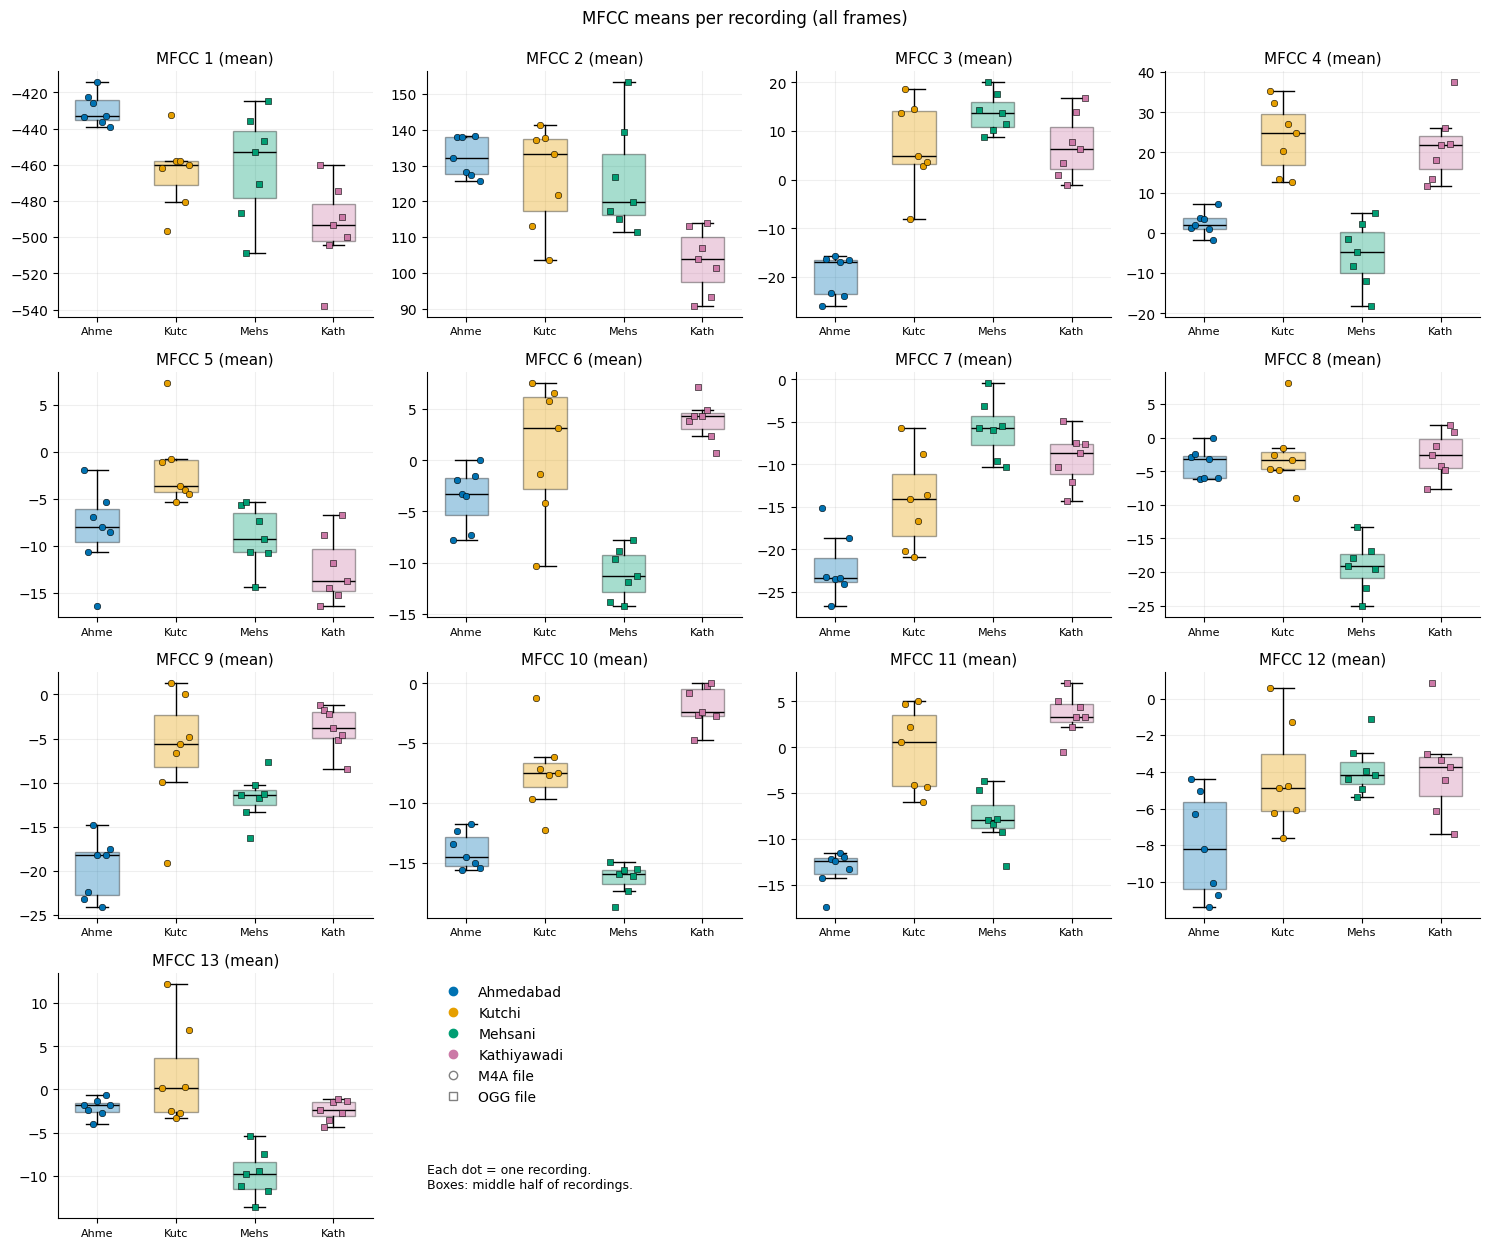

saved: results/feature_analysis/figures/02_mfcc_stds_by_accent.png


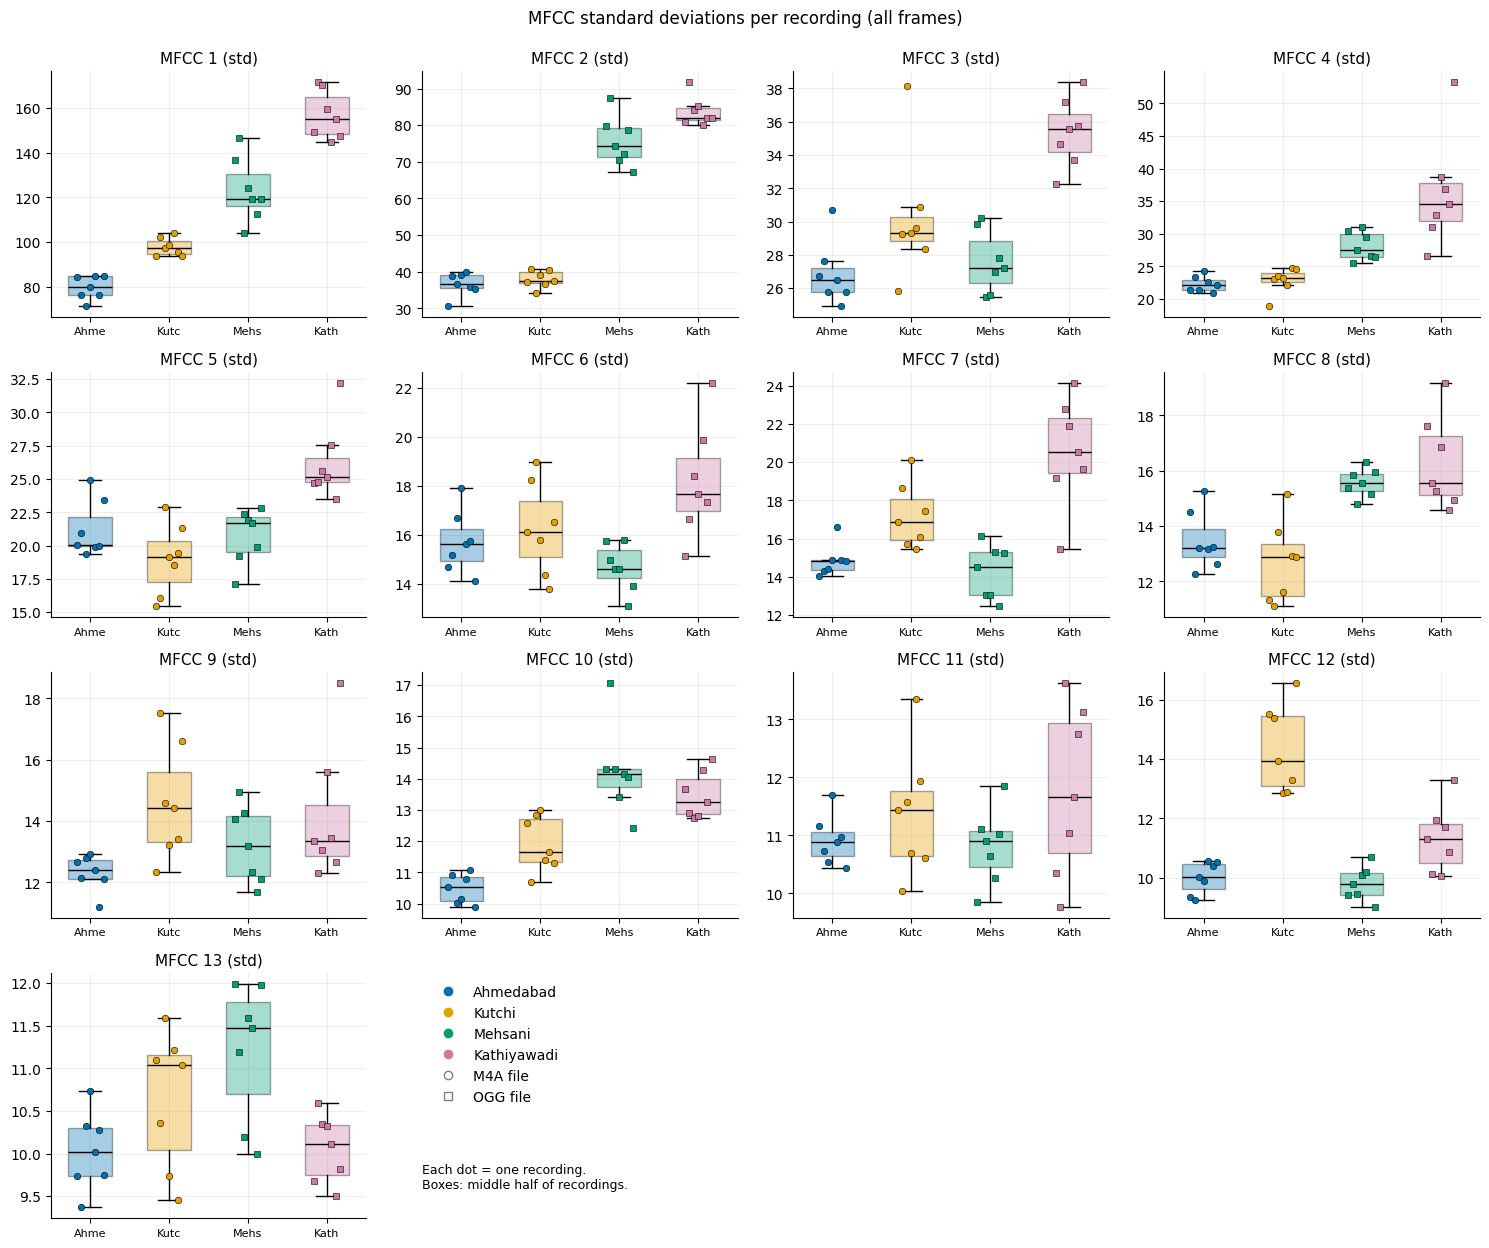

saved: results/feature_analysis/figures/03_delta_means_by_accent.png


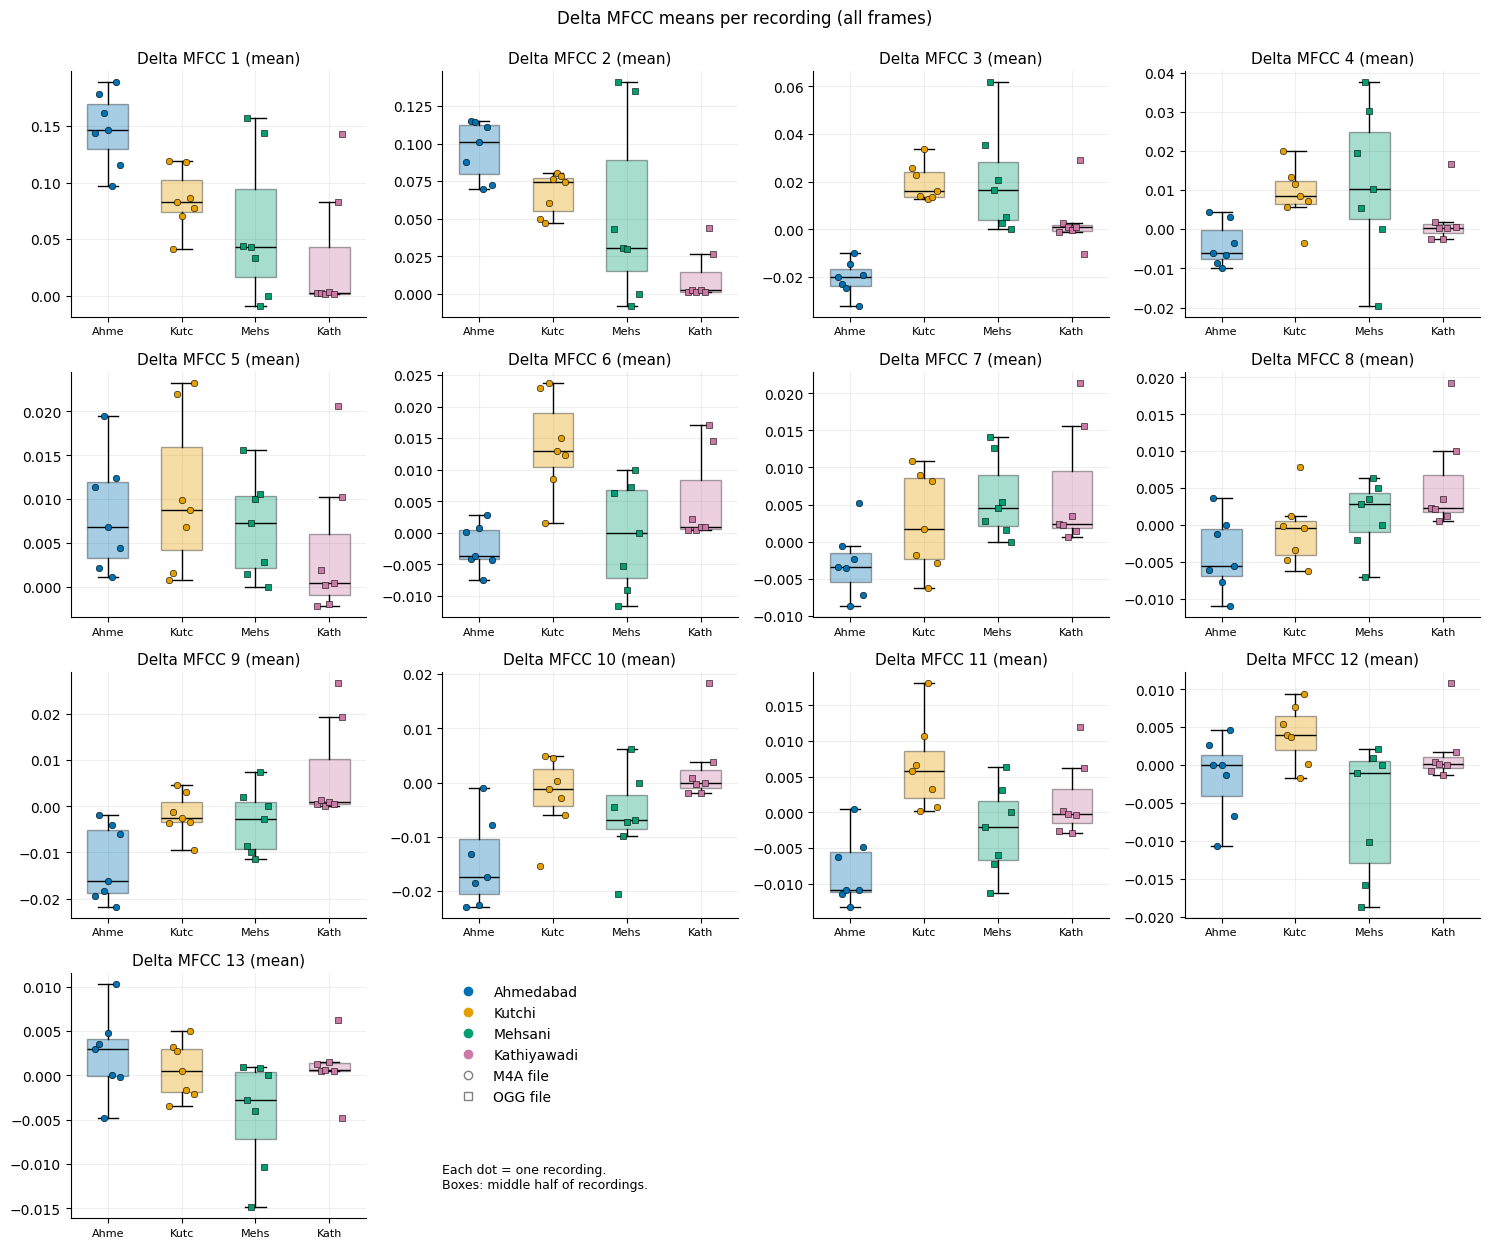

saved: results/feature_analysis/figures/04_delta_stds_by_accent.png


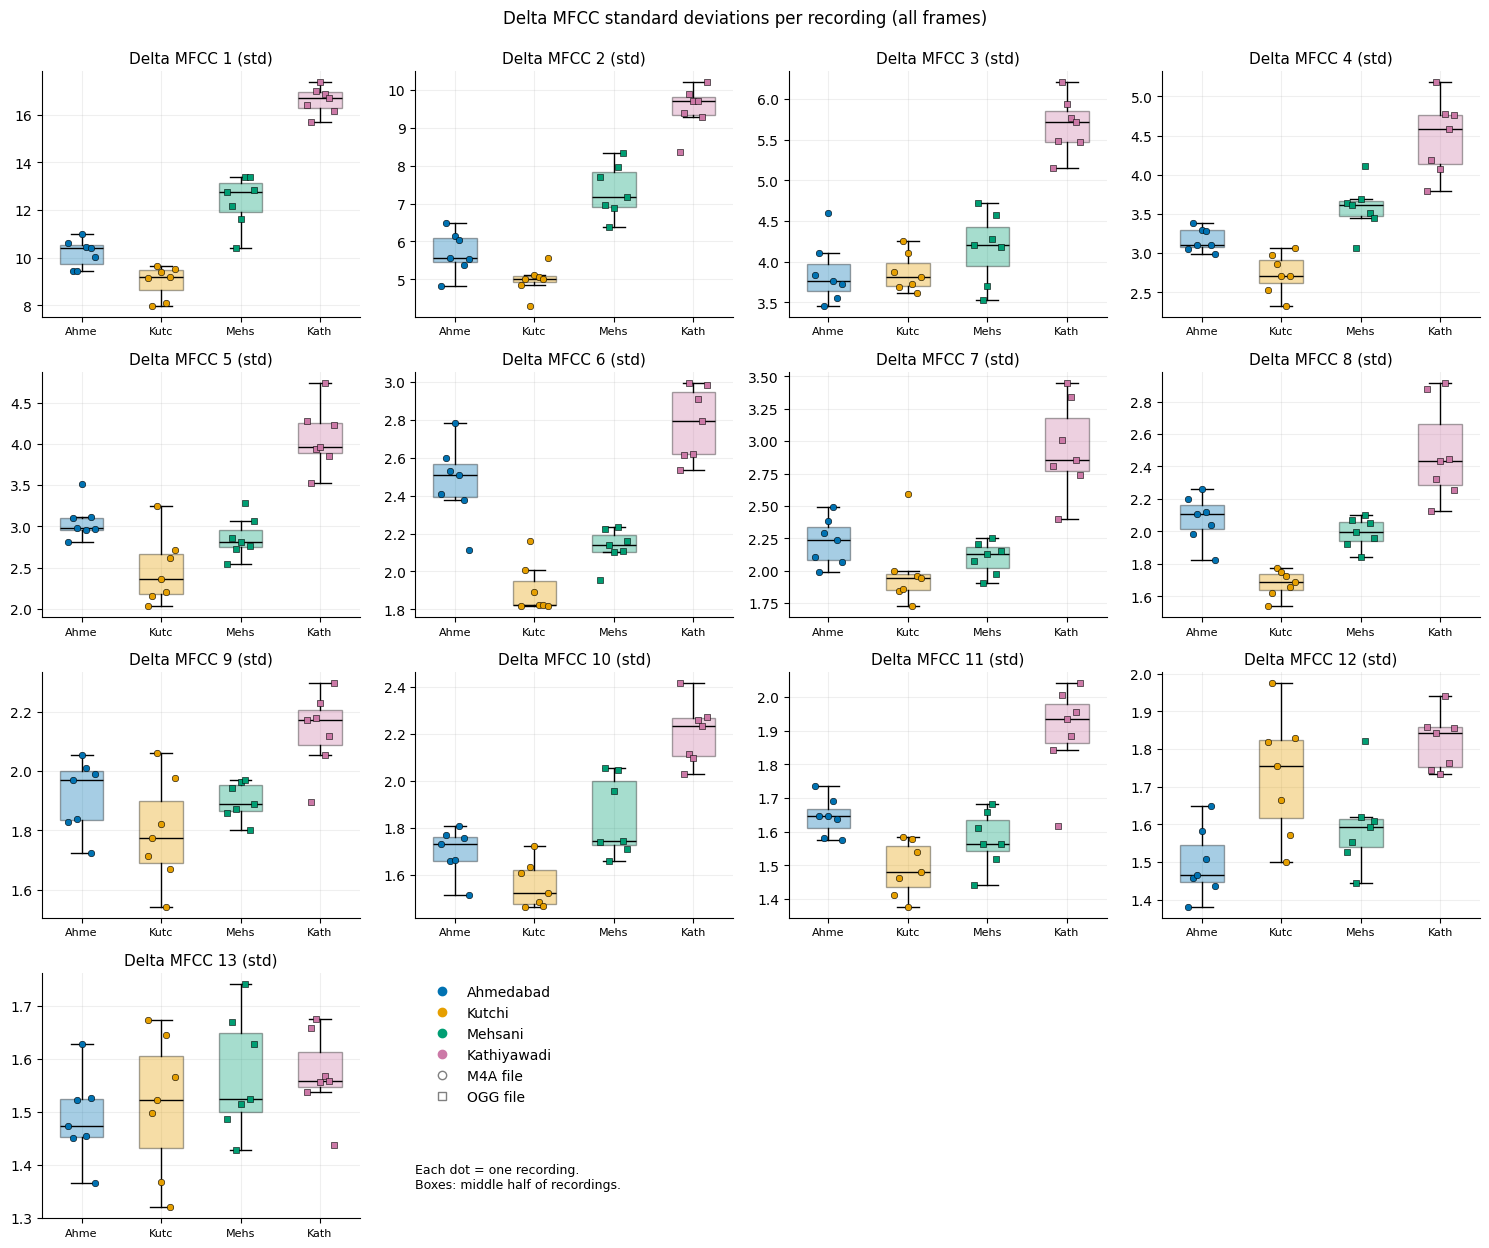

saved: results/feature_analysis/figures/05_delta2_means_by_accent.png


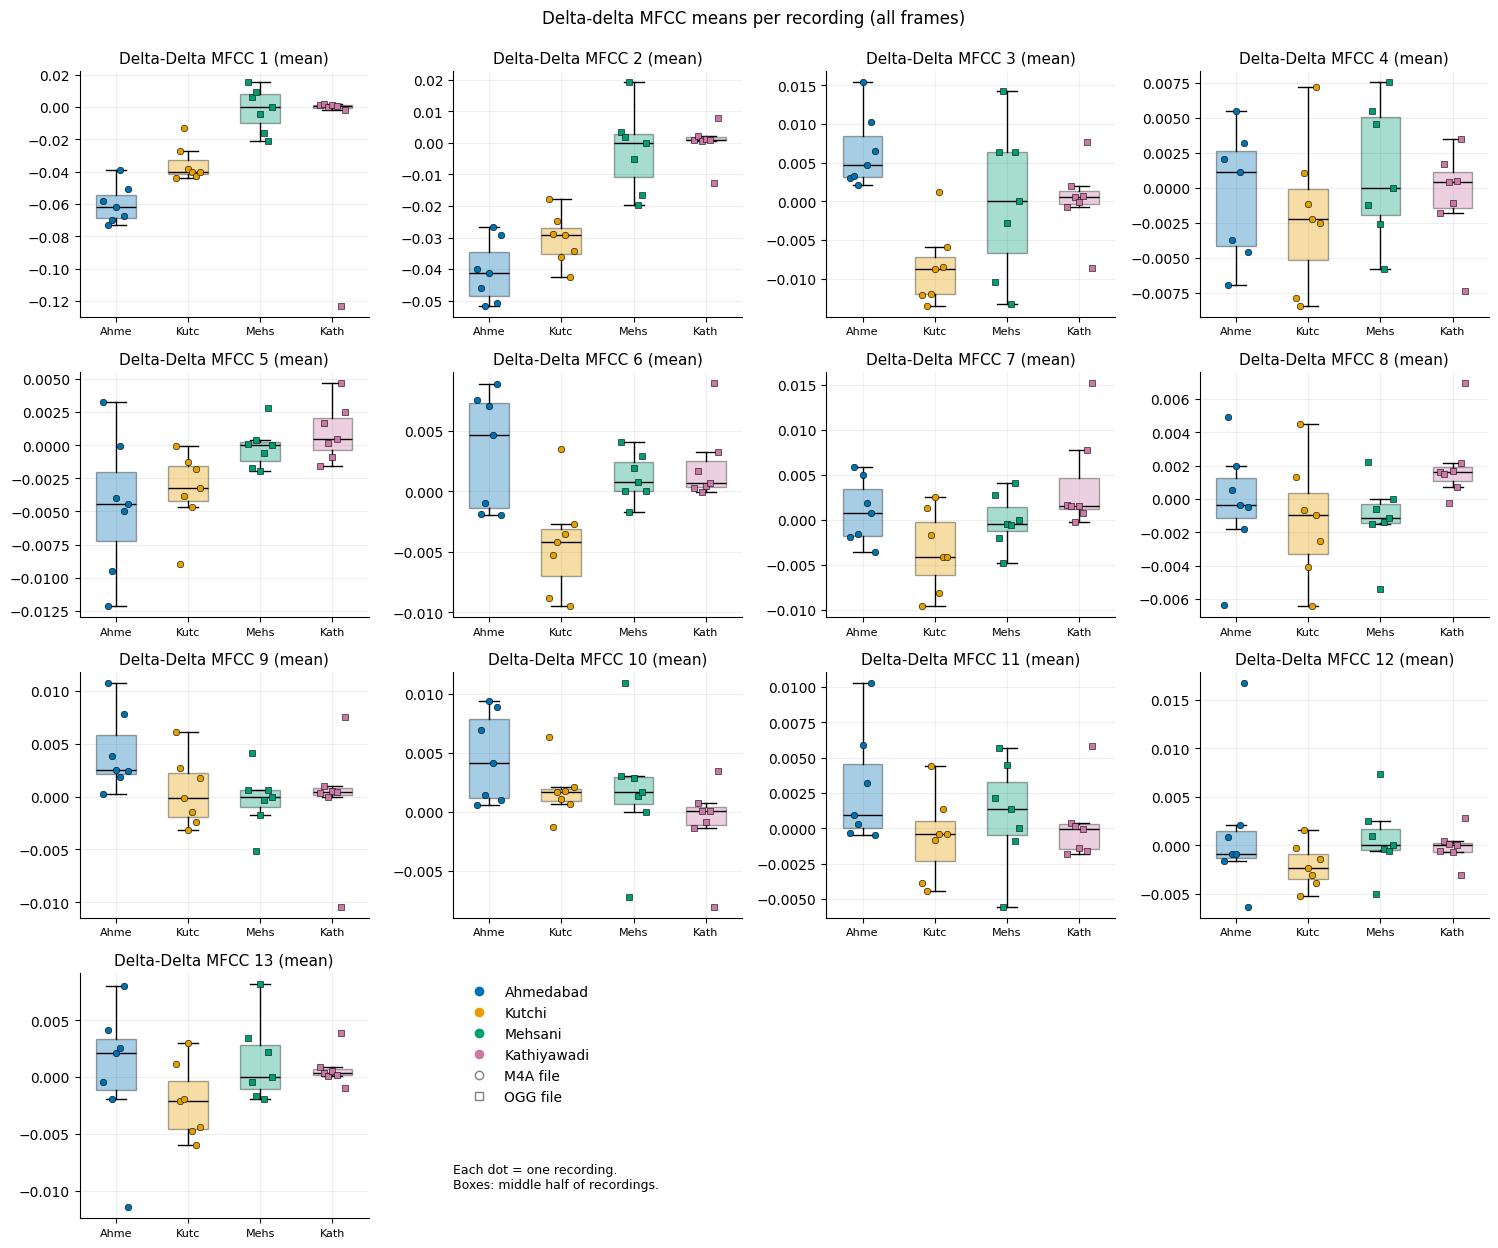

saved: results/feature_analysis/figures/06_delta2_stds_by_accent.png


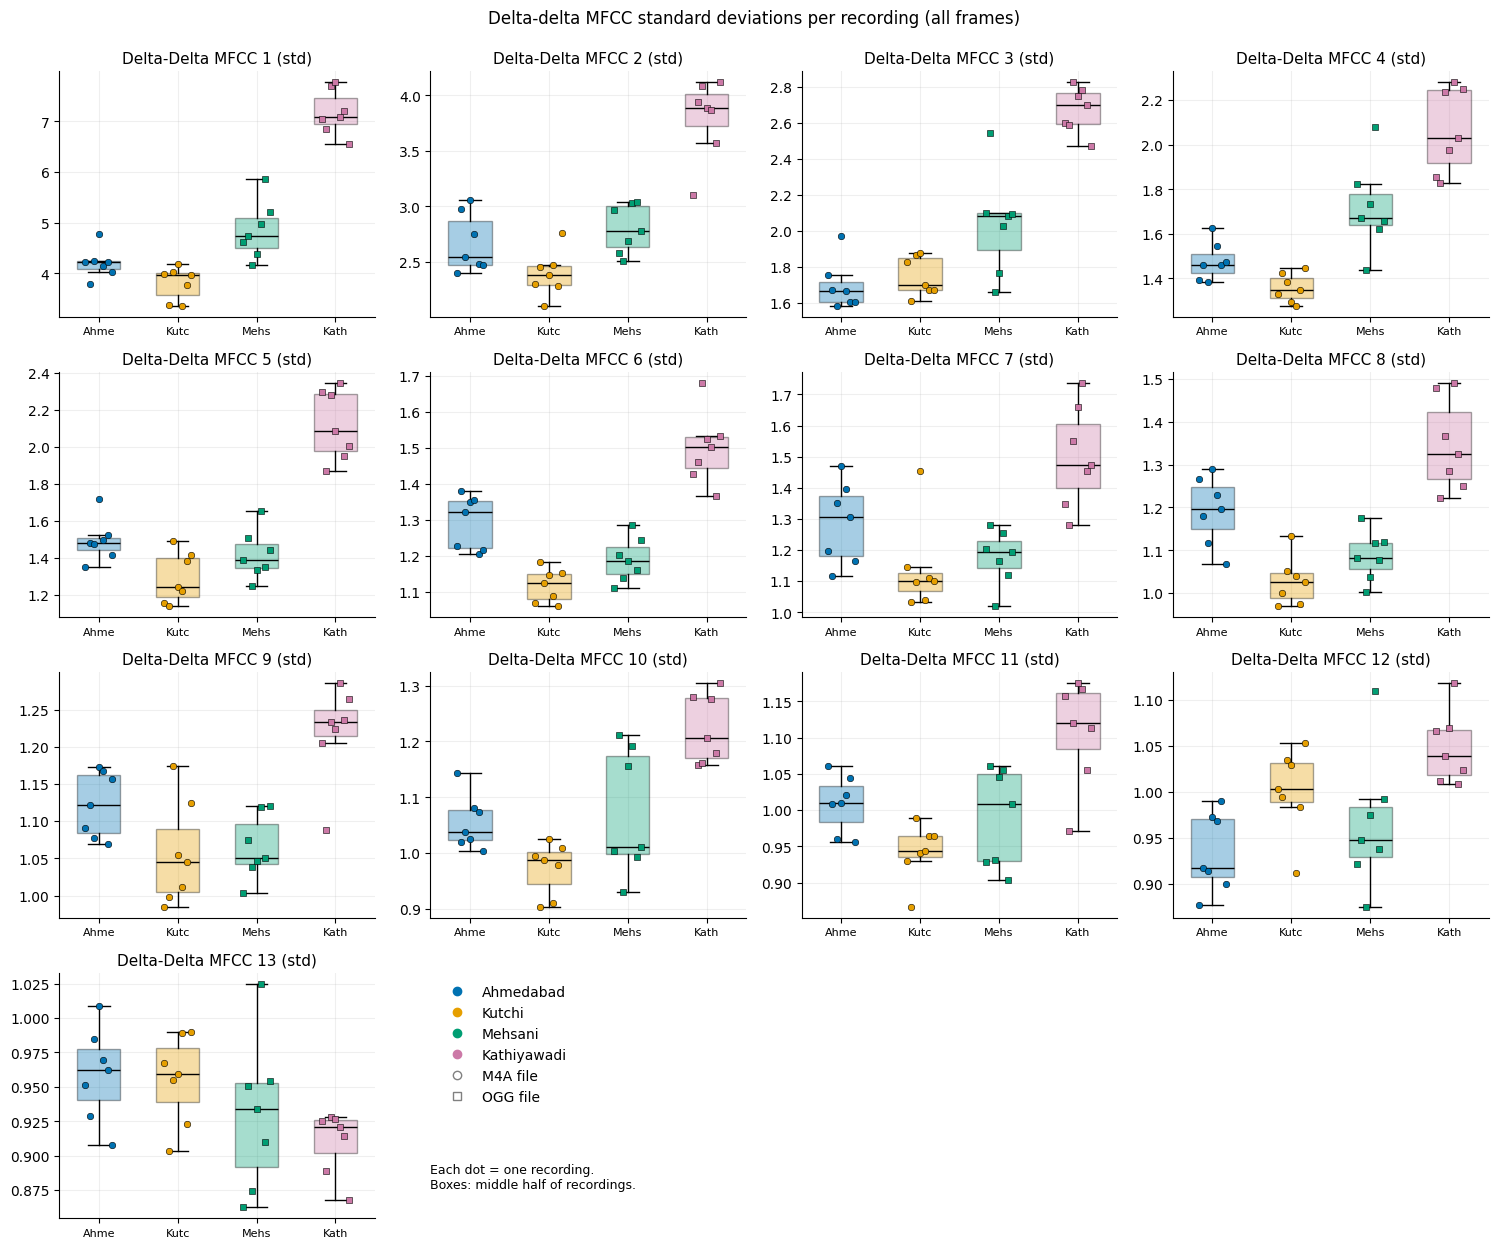

In [5]:
specs = [("mfcc", "mean", "01_mfcc_means_by_accent.png", "MFCC means per recording (all frames)"),
         ("mfcc", "std", "02_mfcc_stds_by_accent.png", "MFCC standard deviations per recording (all frames)"),
         ("delta", "mean", "03_delta_means_by_accent.png", "Delta MFCC means per recording (all frames)"),
         ("delta", "std", "04_delta_stds_by_accent.png", "Delta MFCC standard deviations per recording (all frames)"),
         ("delta2", "mean", "05_delta2_means_by_accent.png", "Delta-delta MFCC means per recording (all frames)"),
         ("delta2", "std", "06_delta2_stds_by_accent.png", "Delta-delta MFCC standard deviations per recording (all frames)")]
for g, s, name, title in specs:
    FIGS.append(name)
    fp.feature_grid(T, g, s, ACCENTS, COLORS, MARKERS, title, name)

## C. Feature distributions and overlap
Three views of overlap:

1. **Frame-level distributions** (violins and histograms) for MFCC 1-4. These four were chosen by a fixed, a-priori rule (the first four coefficients describe the broad shape and energy of the spectrum), *not* because they look different between accents.
2. **Pairwise plots** of the recording-level means of the same four coefficients.
3. **Two overlap measures for all 78 features**, calculated on the recording-level values:
   - **eta-squared (eta^2)**: the share of a feature's variation between recordings that is explained by which accent group the recording belongs to (0 = none, 1 = all). By pure chance alone, with 28 recordings and 4 groups, it averages about 0.11. It is a *descriptive* size, with **no p-value**.
   - **Disjoint accent pairs**: out of all accent pairs, how many have completely non-overlapping value ranges (every recording of one accent lies outside the range of the other).
   Because each accent is one speaker, "explained by accent" really means "explained by accent + speaker + recording setup + wording".

In [6]:
ids_by_accent = {a: list(T.loc[T.accent == a, "recording_id"]) for a in ACCENTS}
# (Section C uses all frames; speech-only versions of the violins are in Section D)

In [7]:
def sep_table(tbl):
    rows = []
    for f in F:
        ok = tbl[f].notna(); t = tbl[ok]
        g, k, s = fa.split_feature_name(f)
        n_dis, n_pairs = fa.disjoint_pairs(t[f], t.accent) if t.accent.nunique() > 1 else (0, 0)
        rows.append(dict(feature=f, feature_group=g, coefficient=k, statistic=s,
                         eta2_accent=fa.eta_squared(t[f], t.accent), disjoint_pairs=n_dis, accent_pairs=n_pairs,
                         disjoint_fraction=n_dis / n_pairs if n_pairs else np.nan))
    return pd.DataFrame(rows)

sep_all = sep_table(T)
print("Chance level for eta^2 with %d recordings and %d accents is about %.2f" % (len(T), len(ACCENTS), (len(ACCENTS) - 1) / (len(T) - 1)))
print("Features by overlap class (all frames, eta^2 thresholds: high >= %.2f, moderate >= %.2f):" % (fa.ETA_HIGH, fa.ETA_MODERATE))
print(sep_all.eta2_accent.map(fa.separation_class).value_counts().to_string())

Chance level for eta^2 with 28 recordings and 4 accents is about 0.11
Features by overlap class (all frames, eta^2 thresholds: high >= 0.60, moderate >= 0.30):
eta2_accent
high        38
moderate    25
low         15


saved: results/feature_analysis/figures/07_violin_frames_mfcc1to4.png


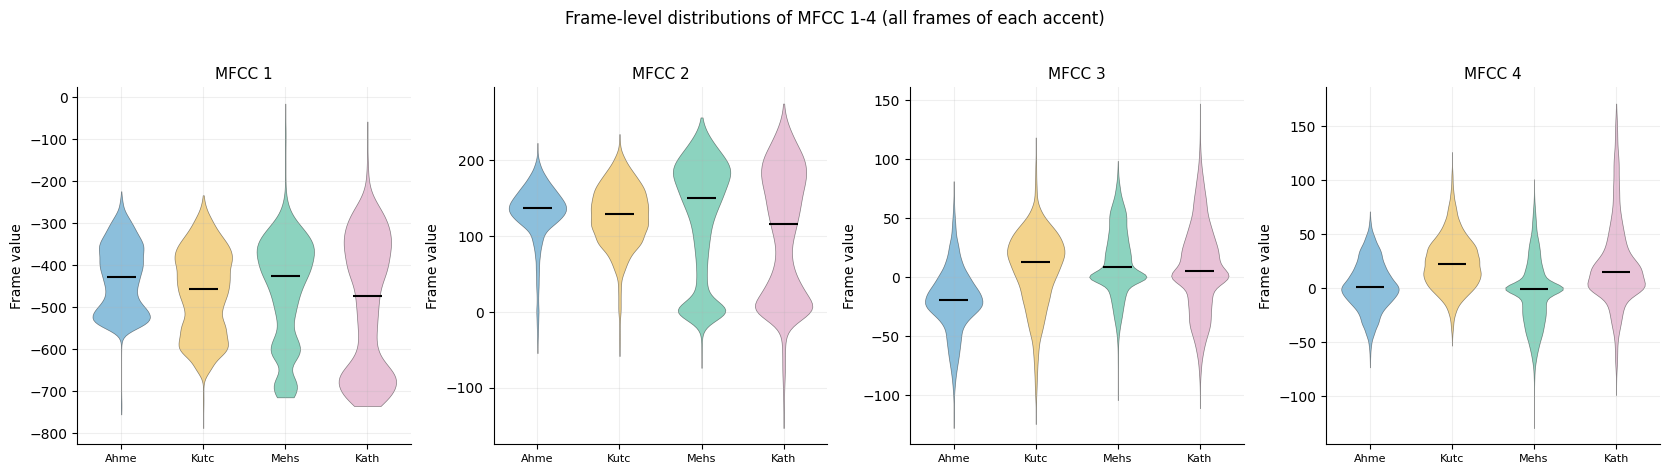

saved: results/feature_analysis/figures/08_hist_frames_mfcc1to4.png


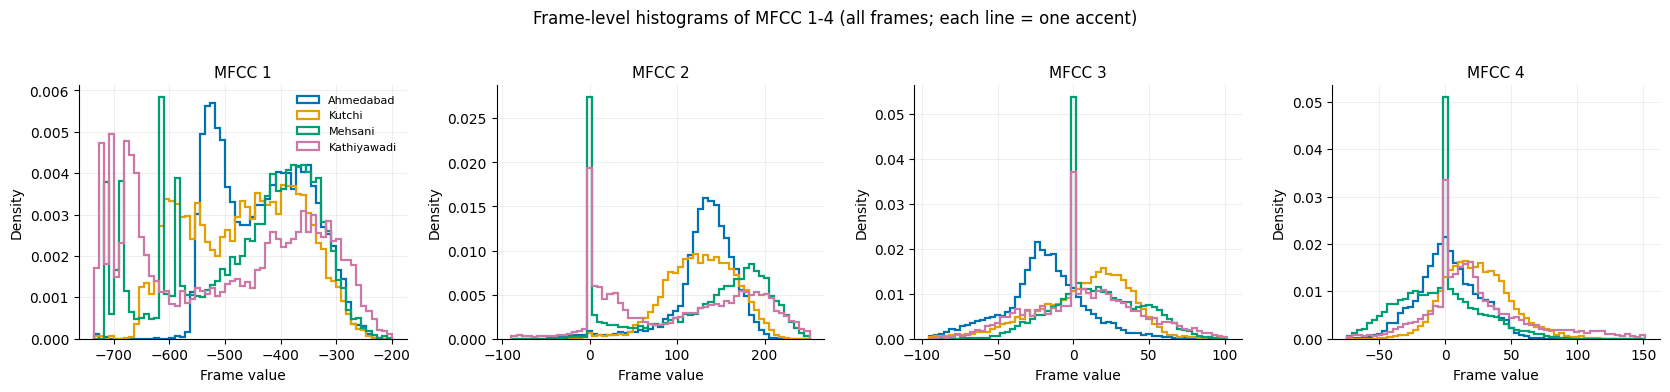

In [8]:
# Violin plots + histograms of frame-level values (MFCC 1-4), all frames
import feature_plots
masks_all_true = {rid: np.ones(mf.load_frame_npz(rid)["mfcc"].shape[1], bool) for a in ACCENTS for rid in ids_by_accent[a]}
FIGS.append("07_violin_frames_mfcc1to4.png")
feature_plots.violin_frames(ids_by_accent, masks_all_true, [1, 2, 3, 4], ACCENTS, COLORS,
                            "07_violin_frames_mfcc1to4.png", "Frame-level distributions of MFCC 1-4 (all frames of each accent)", compare=False)
FIGS.append("08_hist_frames_mfcc1to4.png")
feature_plots.hist_frames(ids_by_accent, [1, 2, 3, 4], ACCENTS, COLORS, "08_hist_frames_mfcc1to4.png",
                          "Frame-level histograms of MFCC 1-4 (all frames; each line = one accent)")

saved: results/feature_analysis/figures/09_pairwise_mfcc_means_1to4.png


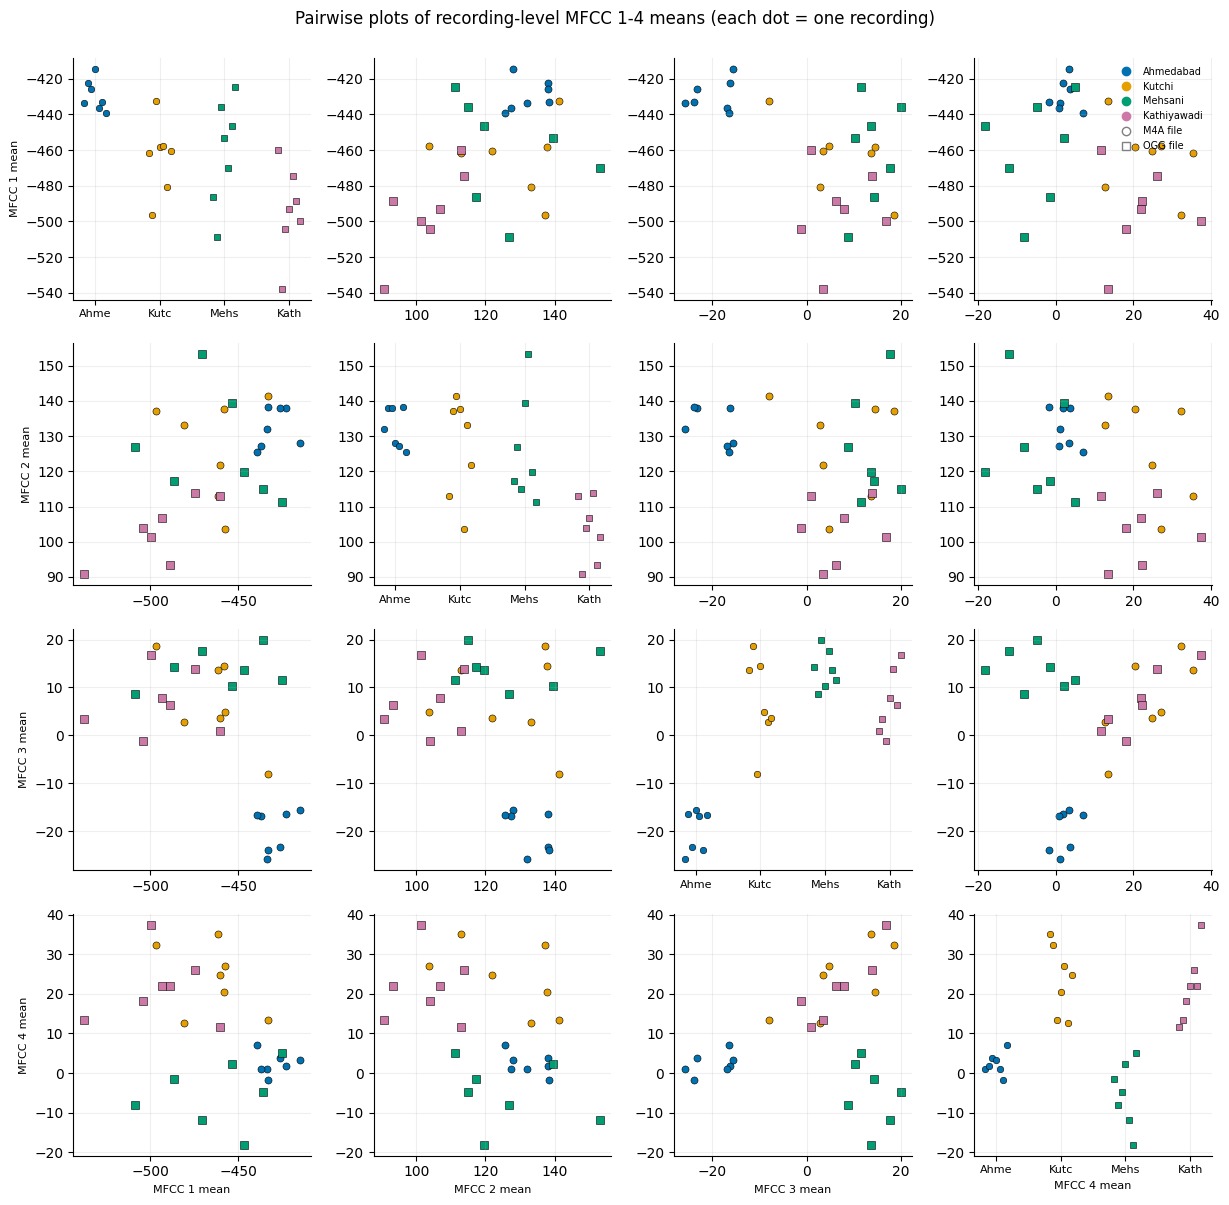

In [9]:
FIGS.append("09_pairwise_mfcc_means_1to4.png")
feature_plots.pairwise_means(T, [f"mfcc_{k:02d}_mean" for k in (1, 2, 3, 4)], ACCENTS, COLORS, MARKERS,
                             "09_pairwise_mfcc_means_1to4.png", "Pairwise plots of recording-level MFCC 1-4 means (each dot = one recording)")

saved: results/feature_analysis/figures/10_accent_separation_heatmaps_all_frames.png


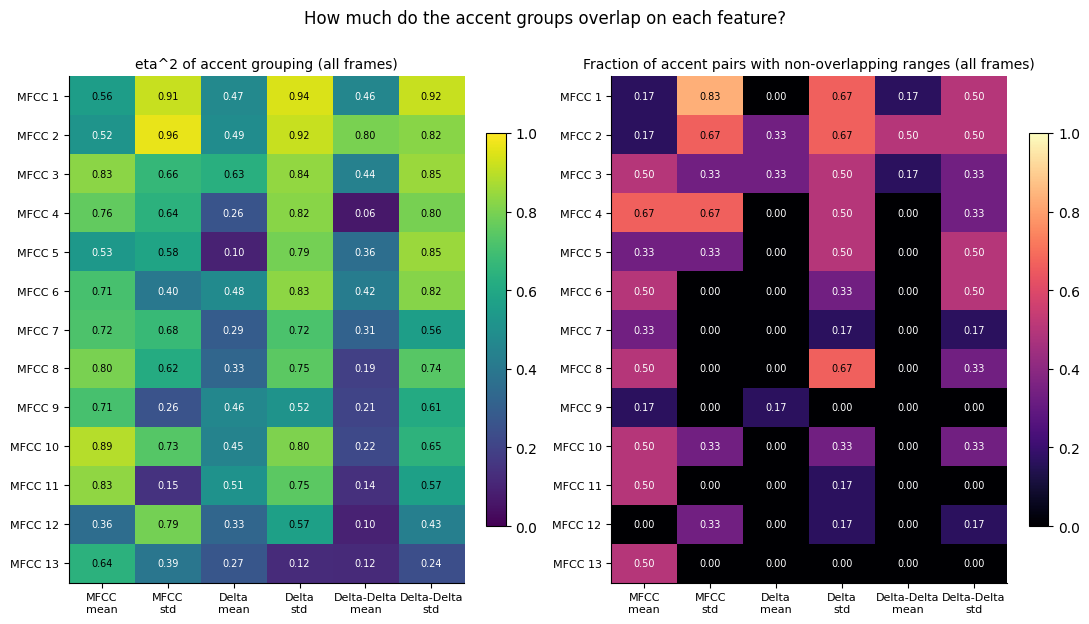

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.2))
im1 = fp.coef_heatmap(axes[0], sep_all.rename(columns={"eta2_accent": "v"}), "v", "eta^2 of accent grouping (all frames)")
im2 = fp.coef_heatmap(axes[1], sep_all.rename(columns={"disjoint_fraction": "v"}), "v", "Fraction of accent pairs with non-overlapping ranges (all frames)", cmap="magma")
fig.colorbar(im1, ax=axes[0], fraction=0.045); fig.colorbar(im2, ax=axes[1], fraction=0.045)
fig.suptitle("How much do the accent groups overlap on each feature?", y=1.0)
fig.tight_layout(); save(fig, "10_accent_separation_heatmaps_all_frames.png")

**Correlations between features.** Because many MFCC features move together, we also look at how the 78 recording-level features correlate with each other across the 28 recordings (Pearson, -1 to +1). Saved as `feature_correlations.csv` (78 x 78 matrix). With 28 recordings that come from only four speakers, treat these as rough descriptive numbers.

saved feature_correlations.csv (78, 78)


saved: results/feature_analysis/figures/11_feature_correlation_heatmap.png


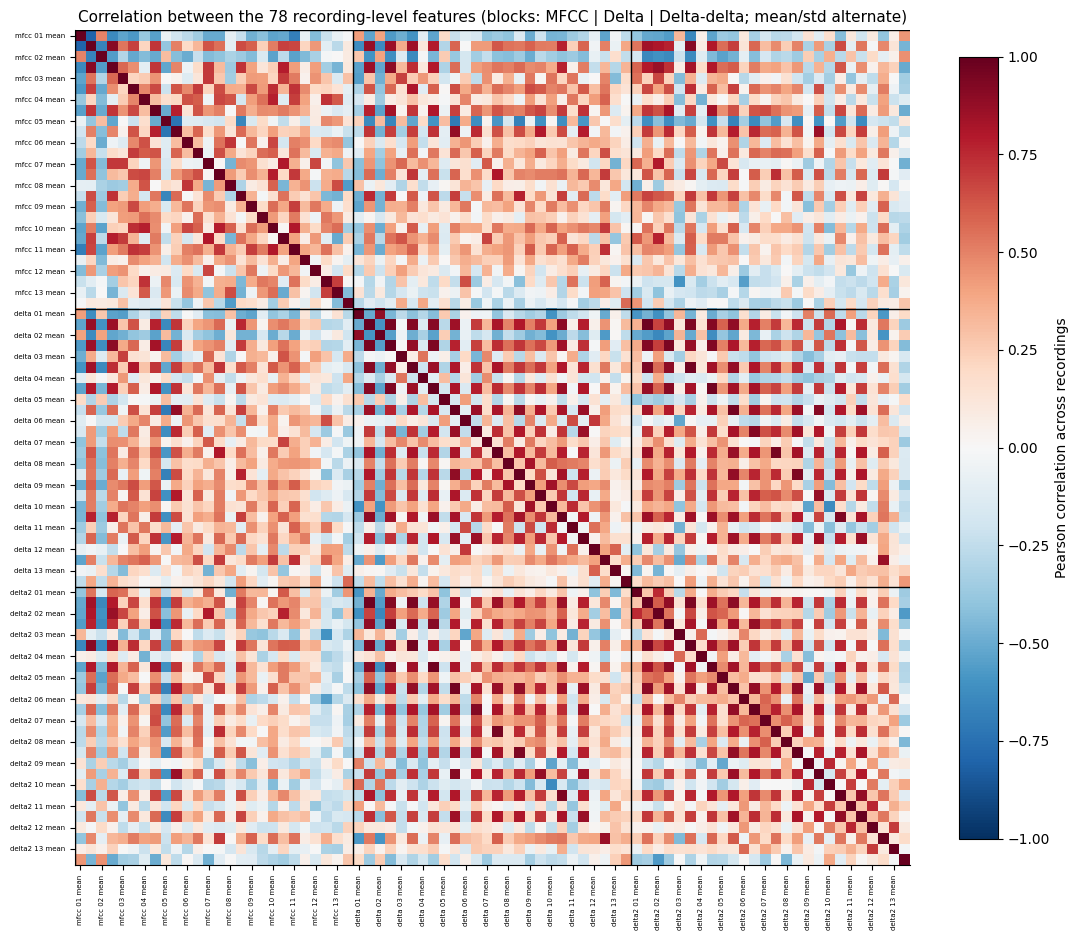

Feature pairs with |r| >= 0.9: 23 of 3003


,level_0,level_1,r
1753,delta_01_std,delta2_01_std,0.976
2038,delta_04_std,delta2_04_std,0.967
1947,delta_03_std,delta2_03_std,0.963
2125,delta_05_std,delta2_05_std,0.958
2287,delta_07_std,delta2_07_std,0.953
1729,delta_01_std,delta_02_std,0.952
1852,delta_02_std,delta2_02_std,0.945
1943,delta_03_std,delta2_01_std,0.943


In [11]:
corr = T[F].corr(method="pearson")
corr.to_csv(fa.FA_DIR / "feature_correlations.csv")
print("saved feature_correlations.csv", corr.shape)
FIGS.append("11_feature_correlation_heatmap.png")
feature_plots.correlation_heatmap(corr, "11_feature_correlation_heatmap.png",
                                  "Correlation between the 78 recording-level features (blocks: MFCC | Delta | Delta-delta; mean/std alternate)")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("r").reset_index()
pairs["abs_r"] = pairs.r.abs()
print("Feature pairs with |r| >= 0.9:", int((pairs.abs_r >= 0.9).sum()), "of", len(pairs))
display(pairs.sort_values("abs_r", ascending=False).head(8)[["level_0", "level_1", "r"]].round(3))

In [12]:
print("Features with the HIGHEST accent-group eta^2 (all frames) - overlap is smallest:")
display(sep_all.sort_values("eta2_accent", ascending=False).head(8)[["feature", "eta2_accent", "disjoint_pairs", "accent_pairs"]].round(2))
print("Features with the LOWEST eta^2 - the accents overlap heavily:")
display(sep_all.sort_values("eta2_accent").head(8)[["feature", "eta2_accent", "disjoint_pairs", "accent_pairs"]].round(2))

Features with the HIGHEST accent-group eta^2 (all frames) - overlap is smallest:


,feature,eta2_accent,disjoint_pairs,accent_pairs
3,mfcc_02_std,0.96,4,6
27,delta_01_std,0.94,4,6
53,delta2_01_std,0.92,3,6
29,delta_02_std,0.92,4,6
1,mfcc_01_std,0.91,5,6
18,mfcc_10_mean,0.89,3,6
57,delta2_03_std,0.85,2,6
61,delta2_05_std,0.85,3,6


Features with the LOWEST eta^2 - the accents overlap heavily:


,feature,eta2_accent,disjoint_pairs,accent_pairs
58,delta2_04_mean,0.06,0,6
34,delta_05_mean,0.10,0,6
74,delta2_12_mean,0.10,0,6
76,delta2_13_mean,0.12,0,6
51,delta_13_std,0.12,0,6
72,delta2_11_mean,0.14,0,6
21,mfcc_11_std,0.15,0,6
66,delta2_08_mean,0.19,0,6


## D. Silence and speech
Phase 3 found that the mean of MFCC 1 and MFCC 2 per recording moves with the **share of speech frames**. Here we test this directly by separating **speech frames** from **non-speech frames** and re-summarising the features on speech frames only.

**Is the alignment reliable? (verified, not assumed)** The Phase 2 speech detector did not save its frame-by-frame labels, so we recompute them with the *same Phase 2 function* on the same WAV files (read-only). A recording is used for speech-only features only if **all** of these hold:
1. the mask has exactly as many frames as the MFCC matrix;
2. both use a 160-sample hop, a 400-sample window and *centred* frames, so frame *i* is centred on the same sample in both, and the NPZ frame times equal *i* x 10 ms;
3. the Phase 2 numbers recomputed here (speech share, leading/trailing silence, pause count) equal the saved Phase 2 CSV;
4. frame energy (dB) correlates with MFCC 1 most strongly within +/-1 frame (10 ms) of zero lag. *Honest note:* I first required exactly zero lag; two noisy Kutchi recordings peak one frame (10 ms) off, so the tolerance became +/-1 frame. That is much smaller than the 25 ms analysis window, and a sensitivity test below shows that shifting the mask by one frame barely changes the results.

Speech-only delta and delta-delta values come from the stored whole-recording matrices (which used neighbouring frames for context) restricted to speech frames. The whole-recording features are not changed.

C:\Users\91966\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Recordings with reliable alignment: 28 of 28
  same_frame_count            : 28/28
  same_framing_parameters     : 28/28
  frame_times_match           : 28/28
  phase2_scalars_reproduced   : 28/28
  best_lag_within_one_frame   : 28/28
  best lag = 0 frames          : 26 | best lag = +/-1 frame: 2
  correlation at lag 0 (energy vs MFCC 1): min 0.84, median 0.90


saved: results/feature_analysis/figures/12_alignment_check.png


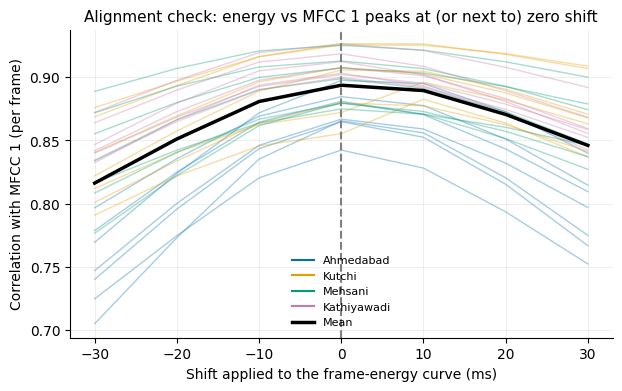

In [13]:
speech, lags = fa.compute_speech_frames(data["meta"], list(T.recording_id))
align = pd.DataFrame([{"recording_id": r, **v["mask_checks"], "best_lag_frames": v["best_lag_frames"],
                       "r_energy_vs_mfcc1_at_lag0": round(v["r_at_lag0"], 3), "aligned": v["aligned"]} for r, v in speech.items()])
print("Recordings with reliable alignment:", int(align.aligned.sum()), "of", len(align))
for col in [c for c in align.columns if c in ("same_frame_count", "same_framing_parameters", "frame_times_match", "phase2_scalars_reproduced", "best_lag_within_one_frame")]:
    print(f"  {col:<28}: {int(align[col].sum())}/{len(align)}")
print("  best lag = 0 frames          :", int((align.best_lag_frames == 0).sum()), "| best lag = +/-1 frame:", int((align.best_lag_frames.abs() == 1).sum()))
print("  correlation at lag 0 (energy vs MFCC 1): min %.2f, median %.2f" % (align.r_energy_vs_mfcc1_at_lag0.min(), align.r_energy_vs_mfcc1_at_lag0.median()))
assert align.aligned.all(), "Some recordings could not be verified - speech-only features would be unreliable"

fig, ax = plt.subplots(figsize=(7, 4))
ms = lags * 10
for rid, v in speech.items():
    ax.plot(ms, v["lag_r"], color=COLORS[T.set_index("recording_id").loc[rid, "accent"]], alpha=0.35, lw=1)
ax.plot(ms, np.mean([v["lag_r"] for v in speech.values()], axis=0), color="black", lw=2.5, label="Mean of all recordings")
ax.axvline(0, color="grey", ls="--"); ax.set_xlabel("Shift applied to the frame-energy curve (ms)")
ax.set_ylabel("Correlation with MFCC 1 (per frame)"); ax.set_title("Alignment check: energy vs MFCC 1 peaks at (or next to) zero shift")
ax.legend(handles=[plt.Line2D([], [], color=COLORS[a], label=a) for a in ACCENTS] + [plt.Line2D([], [], color="black", lw=2.5, label="Mean")], frameon=False, fontsize=8)
save(fig, "12_alignment_check.png")

In [14]:
sens = fa.shift_sensitivity(speech, 1)
spread = T.groupby("accent")[[f"mfcc_{k:02d}_mean" for k in range(1, 14)]].mean().std()
sens_summary = (sens.groupby("coefficient").abs_change.max().to_frame("max_abs_change_over_all_recordings"))
sens_summary["spread_between_accent_means"] = [spread[f"mfcc_{k:02d}_mean"] for k in sens_summary.index]
sens_summary["change_as_fraction_of_spread"] = sens_summary.max_abs_change_over_all_recordings / sens_summary.spread_between_accent_means
print("Shifting the speech mask by one frame (10 ms) in either direction changes recording-level MFCC means by at most:")
display(sens_summary.round(3).T)

Shifting the speech mask by one frame (10 ms) in either direction changes recording-level MFCC means by at most:


coefficient,1,2,3,4,5,6,7,8,9,10,11,12,13
max_abs_change_over_all_recordings,1.657,1.001,0.685,0.521,0.579,0.303,0.315,0.407,0.296,0.218,0.248,0.230,0.241
spread_between_accent_means,26.463,12.905,14.852,14.292,4.503,6.560,7.068,8.133,7.011,6.519,7.551,2.009,4.756
change_as_fraction_of_spread,0.063,0.078,0.046,0.036,0.129,0.046,0.045,0.050,0.042,0.033,0.033,0.114,0.051


**Speech-only features.** Same 78 columns, but each mean/standard deviation is computed over the speech frames only. The table also reports **how many frames each recording kept**. Saved: `speech_only_recording_features.csv`. Non-speech-only summaries are computed too, to see what the pauses themselves look like.

In [15]:
Tsp, Tns = fa.speech_only_table(T, speech)
assert Tsp[F].notna().all().all() and np.isfinite(Tsp[F].to_numpy(float)).all(), "NaN/inf in speech-only features"
Tsp.to_csv(fa.FA_DIR / "speech_only_recording_features.csv", index=False)
fa.accent_feature_statistics(Tsp, F, ACCENTS).to_csv(fa.FA_DIR / "accent_feature_statistics_speech_only.csv", index=False)
print("saved speech_only_recording_features.csv", Tsp.shape)
retained = Tsp[["recording_id", "accent", "n_frames_total", "n_speech_frames", "pct_speech_frames"]].round(1)
display(retained)
display(retained.groupby("accent")[["n_speech_frames", "pct_speech_frames"]].agg(["min", "mean", "max"]).reindex(ACCENTS).round(1))
print("Total frames: %d, speech frames kept: %d (%.1f%%)" % (retained.n_frames_total.sum(), retained.n_speech_frames.sum(), 100 * retained.n_speech_frames.sum() / retained.n_frames_total.sum()))

saved speech_only_recording_features.csv (28, 87)


,recording_id,accent,n_frames_total,n_speech_frames,pct_speech_frames
0,AHM_S01_R01,Ahmedabad,1419,893,62.9
1,AHM_S01_R02,Ahmedabad,1197,1063,88.8
2,AHM_S01_R03,Ahmedabad,1199,1001,83.5
3,AHM_S01_R04,Ahmedabad,1217,971,79.8
4,AHM_S01_R05,Ahmedabad,1726,1223,70.9
5,AHM_S01_R06,Ahmedabad,1212,951,78.5
6,AHM_S01_R07,Ahmedabad,1645,1207,73.4
7,KUT_S01_R01,Kutchi,1515,1314,86.7
8,KUT_S01_R02,Kutchi,1697,1232,72.6
9,KUT_S01_R03,Kutchi,1541,1229,79.8


n_speech_frames               pct_speech_frames            
                        min    mean   max               min  mean   max
accent                                                                 
Ahmedabad               893  1044.1  1223              62.9  76.8  88.8
Kutchi                  926  1109.3  1314              64.1  73.5  86.7
Mehsani                 730  1031.3  1309              67.5  72.6  80.1
Kathiyawadi             527   702.6   963              49.6  61.2  67.7

Total frames: 38127, speech frames kept: 27211 (71.4%)


saved: results/feature_analysis/figures/13_frames_retained.png


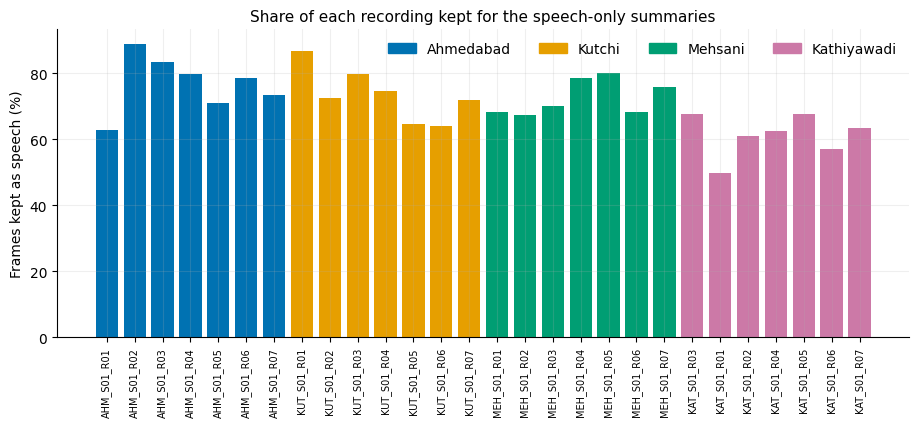

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(Tsp))
ax.bar(x, Tsp.pct_speech_frames, color=[COLORS[a] for a in Tsp.accent])
ax.set_xticks(x); ax.set_xticklabels(Tsp.recording_id, rotation=90, fontsize=7)
ax.set_ylabel("Frames kept as speech (%)"); ax.set_title("Share of each recording kept for the speech-only summaries")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[a], label=a) for a in ACCENTS], frameon=False, ncol=len(ACCENTS))
save(fig, "13_frames_retained.png")

**Whole recording vs speech only.** Dashed lines = original whole-recording means; solid lines = speech-only means (accent averages of the recording-level means). If a coefficient's lines are far apart, silence/noise frames were shaping that feature.

saved: results/feature_analysis/figures/14_allframes_vs_speechonly_profiles.png


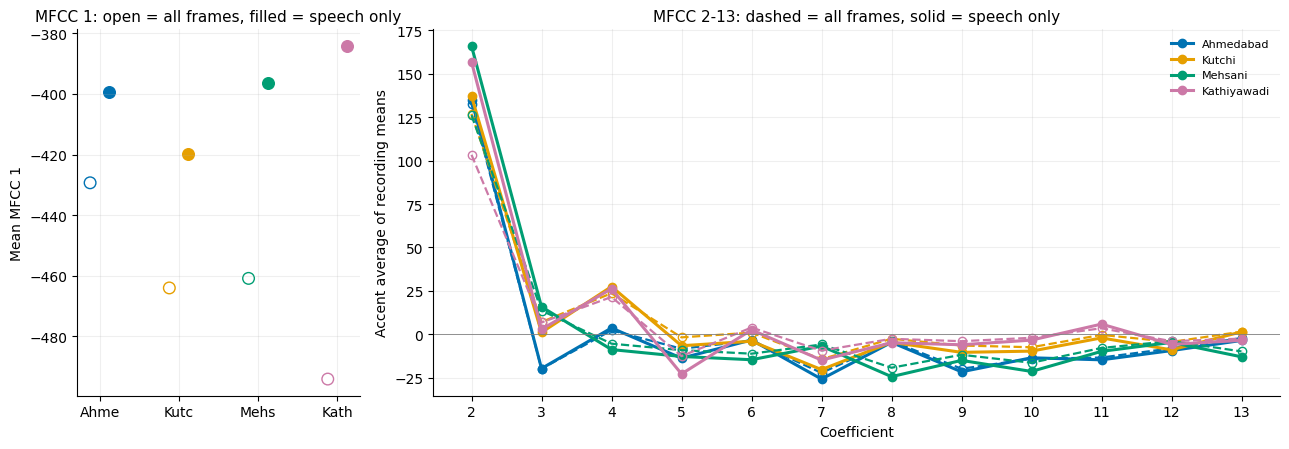

In [17]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 3]})
for a in ACCENTS:
    ma = T[T.accent == a][[f"mfcc_{k:02d}_mean" for k in range(1, 14)]].mean().to_numpy()
    ms_ = Tsp[Tsp.accent == a][[f"mfcc_{k:02d}_mean" for k in range(1, 14)]].mean().to_numpy()
    i = ACCENTS.index(a)
    a0.scatter([i - 0.12], [ma[0]], color=COLORS[a], marker="o", facecolor="none", s=70)
    a0.scatter([i + 0.12], [ms_[0]], color=COLORS[a], marker="o", s=70)
    a1.plot(range(2, 14), ma[1:], color=COLORS[a], ls="--", lw=1.6, marker="o", mfc="none")
    a1.plot(range(2, 14), ms_[1:], color=COLORS[a], lw=2.2, marker="o", label=a)
a0.set_xticks(range(len(ACCENTS))); a0.set_xticklabels([a[:4] for a in ACCENTS]); a0.set_ylabel("Mean MFCC 1"); a0.set_title("MFCC 1: open = all frames, filled = speech only")
a1.set_xticks(range(2, 14)); a1.set_xlabel("Coefficient"); a1.set_ylabel("Accent average of recording means"); a1.axhline(0, color="grey", lw=0.6)
a1.set_title("MFCC 2-13: dashed = all frames, solid = speech only"); a1.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "14_allframes_vs_speechonly_profiles.png")

eta^2 changed by more than 0.15 after restricting to speech frames for 25 of 78 features
Biggest drops:


,feature,eta2_accent_all,eta2_accent_speech,change
36,delta_06_mean,0.48,0.16,-0.32
28,delta_02_mean,0.49,0.27,-0.22
50,delta_13_mean,0.27,0.07,-0.20
3,mfcc_02_std,0.96,0.79,-0.18
26,delta_01_mean,0.47,0.33,-0.15
16,mfcc_09_mean,0.71,0.58,-0.13


Biggest rises:


,feature,eta2_accent_all,eta2_accent_speech,change
34,delta_05_mean,0.10,0.54,0.45
58,delta2_04_mean,0.06,0.50,0.44
60,delta2_05_mean,0.36,0.80,0.44
52,delta2_01_mean,0.46,0.89,0.44
75,delta2_12_std,0.43,0.81,0.38
72,delta2_11_mean,0.14,0.51,0.37


saved: results/feature_analysis/figures/15_eta2_all_vs_speechonly.png


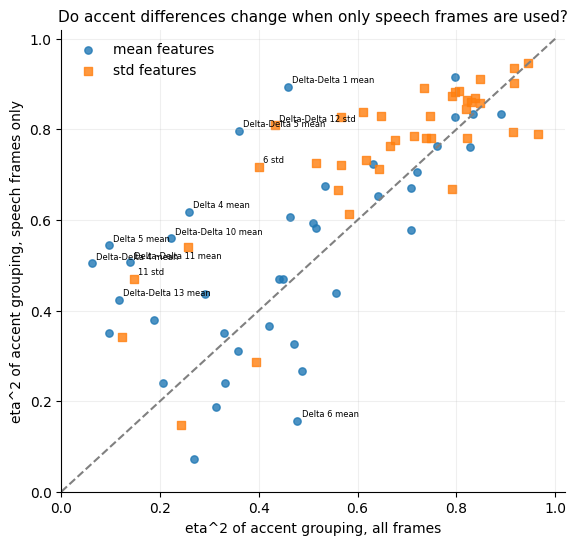

In [18]:
sep_sp = sep_table(Tsp)
eta_cmp = sep_all[["feature", "feature_group", "coefficient", "statistic", "eta2_accent"]].merge(
    sep_sp[["feature", "eta2_accent"]], on="feature", suffixes=("_all", "_speech"))
eta_cmp["change"] = eta_cmp.eta2_accent_speech - eta_cmp.eta2_accent_all
print("eta^2 changed by more than 0.15 after restricting to speech frames for %d of %d features" % ((eta_cmp.change.abs() > 0.15).sum(), len(eta_cmp)))
print("Biggest drops:"); display(eta_cmp.sort_values("change").head(6)[["feature", "eta2_accent_all", "eta2_accent_speech", "change"]].round(2))
print("Biggest rises:"); display(eta_cmp.sort_values("change", ascending=False).head(6)[["feature", "eta2_accent_all", "eta2_accent_speech", "change"]].round(2))

fig, ax = plt.subplots(figsize=(6.5, 6))
for stat, mk in (("mean", "o"), ("std", "s")):
    s = eta_cmp[eta_cmp.statistic == stat]
    ax.scatter(s.eta2_accent_all, s.eta2_accent_speech, marker=mk, s=28, alpha=0.8, label=f"{stat} features")
ax.plot([0, 1], [0, 1], color="grey", ls="--"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
for _, r in eta_cmp[eta_cmp.change.abs() > 0.3].iterrows():
    ax.annotate(fa.feature_label(r.feature).replace("MFCC ", ""), (r.eta2_accent_all, r.eta2_accent_speech), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("eta^2 of accent grouping, all frames"); ax.set_ylabel("eta^2 of accent grouping, speech frames only")
ax.set_title("Do accent differences change when only speech frames are used?"); ax.legend(frameon=False)
save(fig, "15_eta2_all_vs_speechonly.png")

saved: results/feature_analysis/figures/16_violin_all_vs_speechonly_mfcc1to4.png


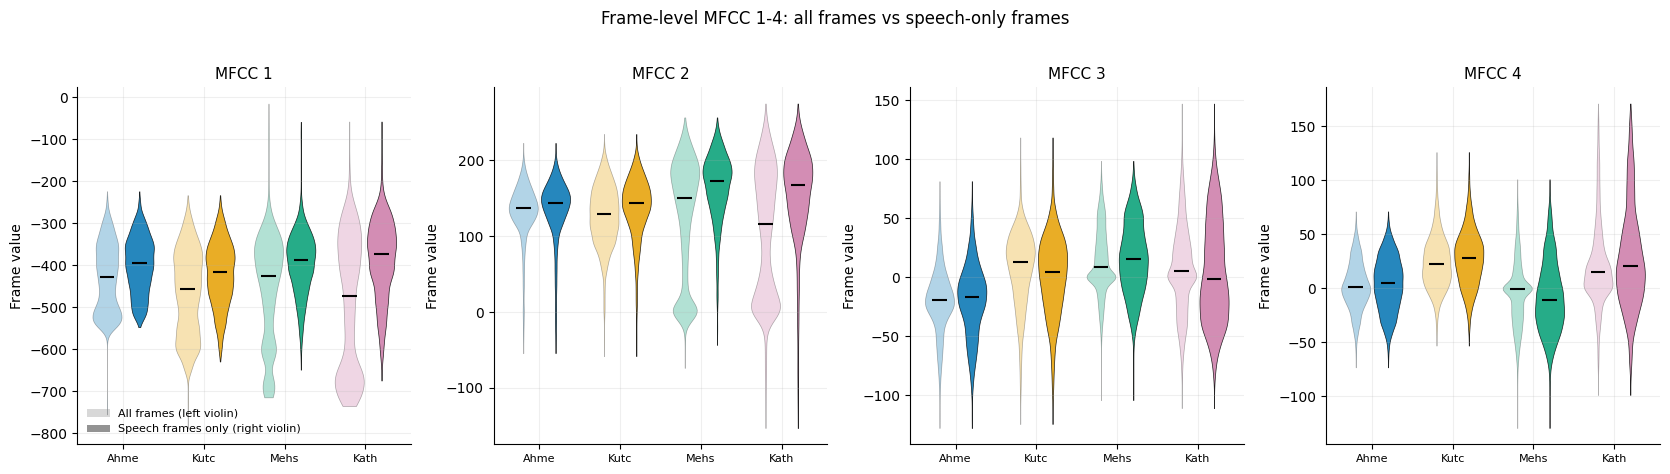

saved: results/feature_analysis/figures/17_speechonly_mfcc_means_by_accent.png


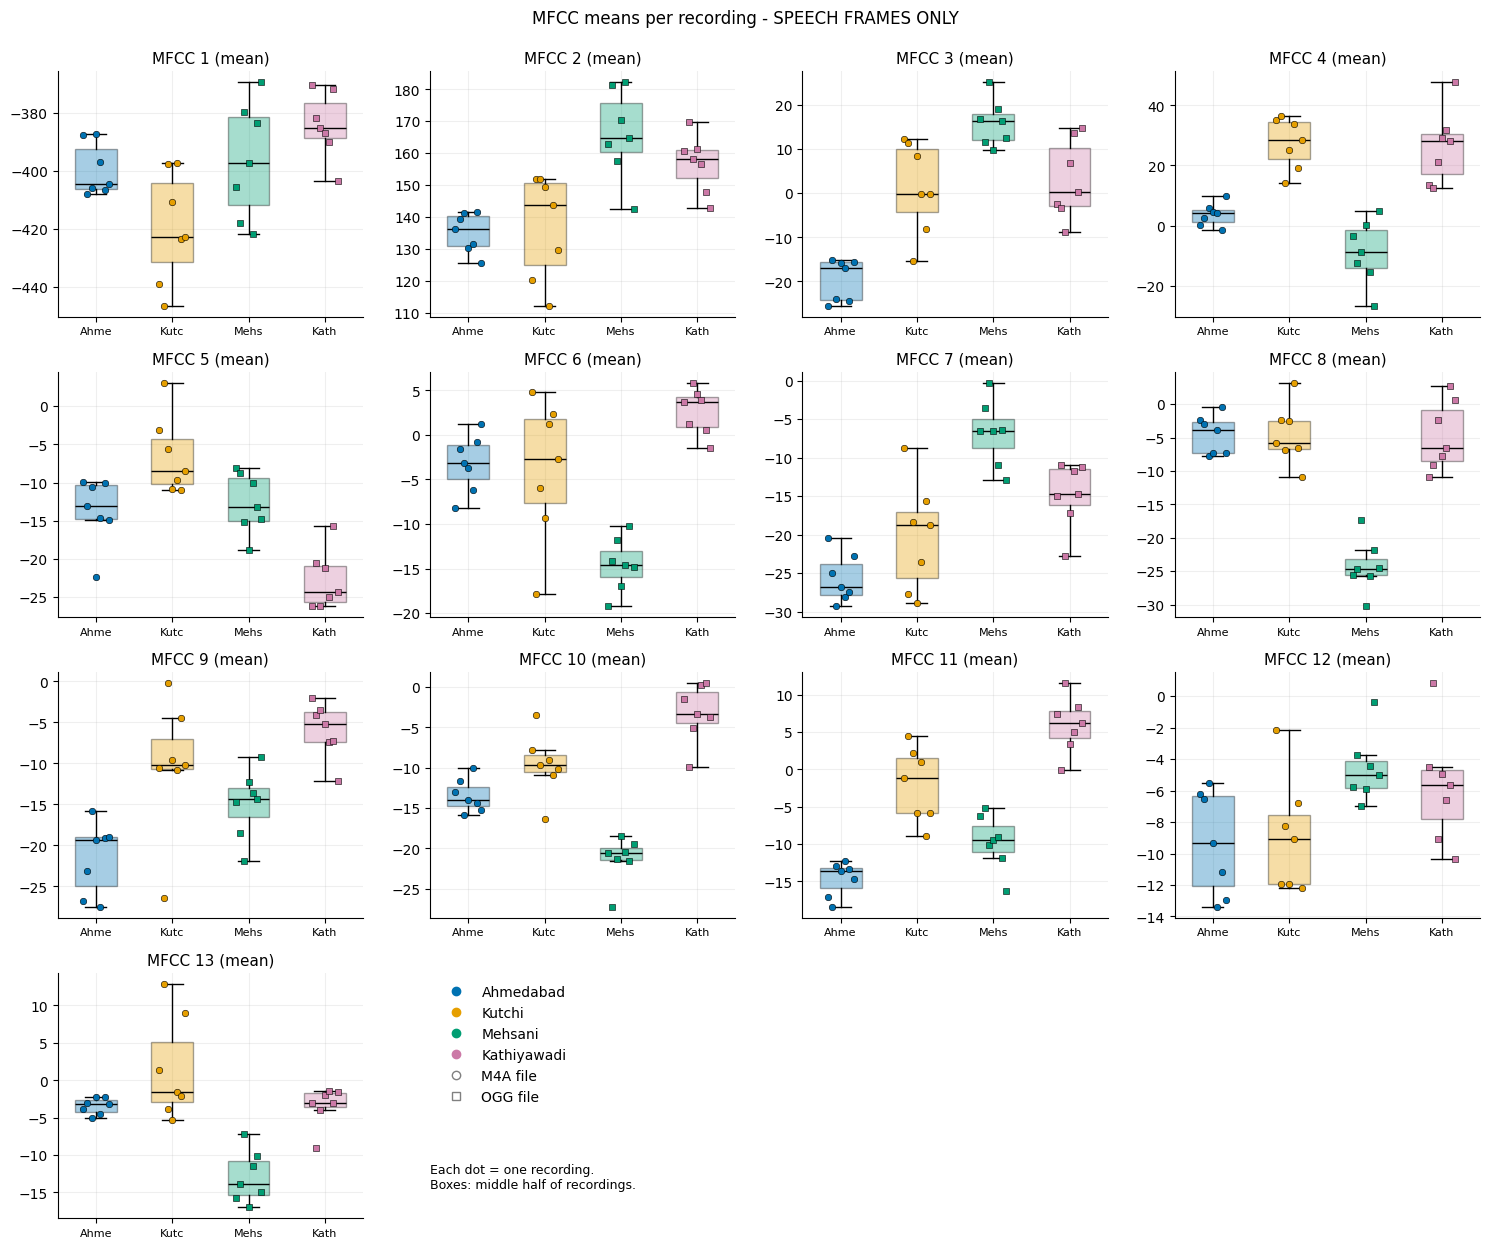

In [19]:
speech_masks = {rid: v["mask"] for rid, v in speech.items()}
FIGS.append("16_violin_all_vs_speechonly_mfcc1to4.png")
feature_plots.violin_frames(ids_by_accent, speech_masks, [1, 2, 3, 4], ACCENTS, COLORS, "16_violin_all_vs_speechonly_mfcc1to4.png",
                            "Frame-level MFCC 1-4: all frames vs speech-only frames", compare=True)
FIGS.append("17_speechonly_mfcc_means_by_accent.png")
feature_plots.feature_grid(Tsp, "mfcc", "mean", ACCENTS, COLORS, MARKERS, "MFCC means per recording - SPEECH FRAMES ONLY",
                           "17_speechonly_mfcc_means_by_accent.png")

**Does the link with the speech share disappear?** For MFCC 1 and MFCC 2 means, each dot is a recording. Left: whole-recording means; right: speech-only means. *r overall* mixes everything together; *r within* removes each accent's own average first, so it only asks whether, *inside one speaker's recordings*, the feature moves with the speech share.

saved: results/feature_analysis/figures/18_speechshare_vs_mfcc12_all_vs_speech.png


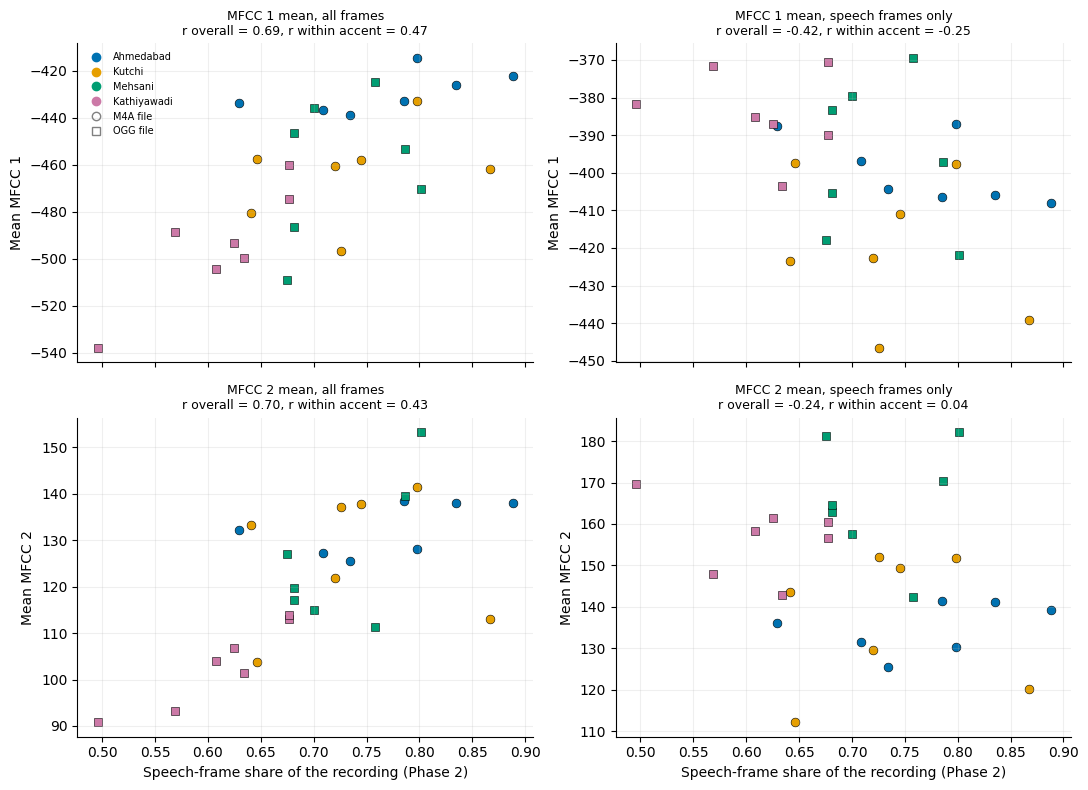

In [20]:
share = T.set_index("recording_id")["speech_ratio"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for row, coef in enumerate((1, 2)):
    col = f"mfcc_{coef:02d}_mean"
    for ax, (tbl, tag) in zip(axes[row], ((T, "all frames"), (Tsp, "speech frames only"))):
        x = tbl.recording_id.map(share).to_numpy(); y = tbl[col].to_numpy()
        for a in ACCENTS:
            for fm in FORMATS:
                m = ((tbl.accent == a) & (tbl.original_format == fm)).to_numpy()
                ax.scatter(x[m], y[m], color=COLORS[a], marker=MARKERS[fm], s=40, edgecolor="black", linewidth=0.4)
        ax.set_title("MFCC %d mean, %s" % (coef, tag) + chr(10) + "r overall = %.2f, r within accent = %.2f" % (fa.corr_overall(x, y), fa.corr_within_accent(x, y, tbl.accent)), fontsize=9)
        ax.set_ylabel("Mean MFCC %d" % coef)
for ax in axes[1]:
    ax.set_xlabel("Speech-frame share of the recording (Phase 2)")
axes[0, 0].legend(handles=fp._legend_handles(ACCENTS, COLORS, FORMATS, MARKERS), frameon=False, fontsize=7)
fig.tight_layout(); save(fig, "18_speechshare_vs_mfcc12_all_vs_speech.png")

**What do the pauses themselves look like?** If MFCC 1 in non-speech frames follows the background noise level, that confirms MFCC 1 mostly reports noise/loudness. Each dot is the mean MFCC 1 over a recording's non-speech frames, against the Phase 2 noise floor.

saved: results/feature_analysis/figures/19_nonspeech_mfcc1_vs_noise.png


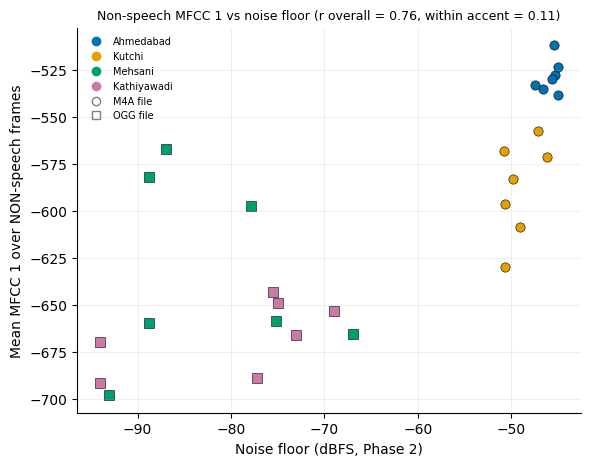

In [21]:
noise = T.set_index("recording_id")["noise_floor_dbfs"]
fig, ax = plt.subplots(figsize=(6.5, 5))
x = Tns.recording_id.map(noise).to_numpy(); y = Tns["mfcc_01_mean"].to_numpy()
for a in ACCENTS:
    for fm in FORMATS:
        m = ((Tns.accent == a) & (Tns.original_format == fm)).to_numpy()
        ax.scatter(x[m], y[m], color=COLORS[a], marker=MARKERS[fm], s=45, edgecolor="black", linewidth=0.4)
ax.set_xlabel("Noise floor (dBFS, Phase 2)"); ax.set_ylabel("Mean MFCC 1 over NON-speech frames")
ax.set_title("Non-speech MFCC 1 vs noise floor (r overall = %.2f, within accent = %.2f)" % (fa.corr_overall(x, y), fa.corr_within_accent(x, y, Tns.accent)), fontsize=9)
ax.legend(handles=fp._legend_handles(ACCENTS, COLORS, FORMATS, MARKERS), frameon=False, fontsize=7)
save(fig, "19_nonspeech_mfcc1_vs_noise.png")
nonspeech_r = (fa.corr_overall(x, y), fa.corr_within_accent(x, y, Tns.accent))

## E. Recording-format effects
Ahmedabad and Kutchi were M4A; Mehsani and Kathiyawadi were OGG. Because format splits the accents in two blocks, we ask for each feature:

- **eta^2 (format)**: how much of its variation is explained just by M4A vs OGG;
- **eta^2 (accent | format)**: of the variation **left over after format**, how much accent still explains (this compares Ahmedabad with Kutchi inside M4A, and Mehsani with Kathiyawadi inside OGG).

A feature with high eta^2(format) and low eta^2(accent | format) mostly splits M4A from OGG. A feature with low eta^2(format) and high eta^2(accent | format) differs *between accents of the same format*, so format alone cannot explain it. (That still does **not** mean it reflects accent: speaker, wording and environment remain confounded.) Whether format *causes* a difference cannot be shown with this data. Saved: `format_comparison.csv`.

In [22]:
fmt_cmp = fa.format_comparison(T, Tsp, F)
fmt_cmp.to_csv(fa.FA_DIR / "format_comparison.csv", index=False)
print("saved format_comparison.csv", fmt_cmp.shape)
fcm = fmt_cmp.copy()
parts = fcm.feature.map(fa.split_feature_name)
fcm["feature_group"] = [p[0] for p in parts]; fcm["coefficient"] = [p[1] for p in parts]; fcm["statistic"] = [p[2] for p in parts]
key = ["mfcc_01_mean", "mfcc_02_mean", "mfcc_03_mean", "mfcc_04_mean", "delta_01_std", "delta_02_std", "delta2_01_std"]
cols = [c for c in fmt_cmp.columns if c.startswith("mean_") and c.endswith("_speech")] + ["eta2_format_all", "eta2_format_speech", "eta2_accent_given_format_all", "eta2_accent_given_format_speech"]
display(fmt_cmp.set_index("label").loc[[fa.feature_label(k) for k in key], cols].round(2))

saved format_comparison.csv (78, 16)


,mean_M4A_speech,mean_OGG_speech,eta2_format_all,eta2_format_speech,eta2_accent_given_format_all,eta2_accent_given_format_speech
label,,,,,,
MFCC 1 mean,-409.57,-390.31,0.25,0.25,0.41,0.25
MFCC 2 mean,136.02,161.34,0.23,0.54,0.37,0.08
MFCC 3 mean,-9.23,9.42,0.35,0.41,0.74,0.60
MFCC 4 mean,15.61,8.78,0.03,0.04,0.75,0.75
Delta MFCC 1 std,10.54,16.22,0.67,0.58,0.83,0.87
Delta MFCC 2 std,5.75,9.08,0.72,0.62,0.71,0.75
Delta-Delta MFCC 1 std,4.31,6.38,0.54,0.46,0.82,0.88


saved: results/feature_analysis/figures/20_format_distributions_selected.png


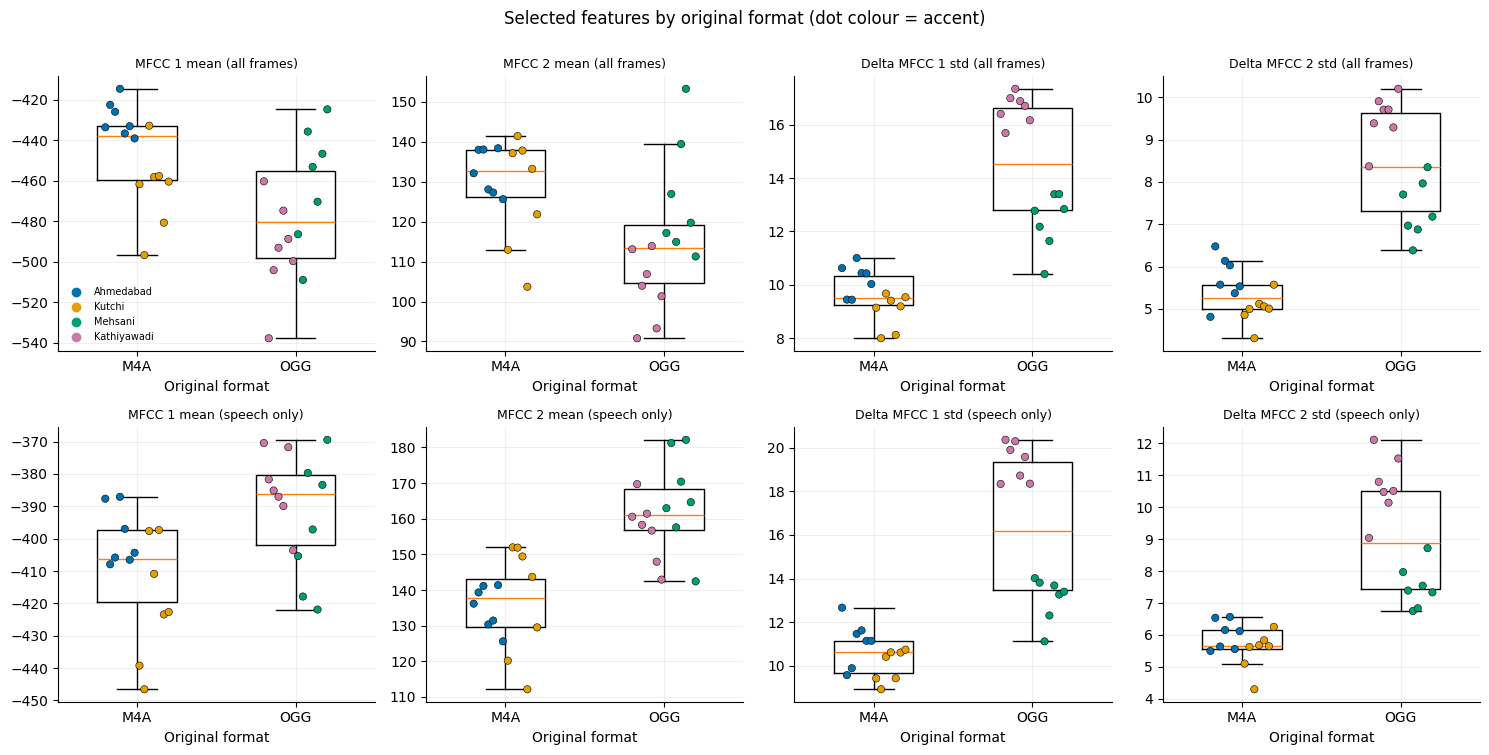

In [23]:
show = [("mfcc_01_mean", "MFCC 1 mean"), ("mfcc_02_mean", "MFCC 2 mean"), ("delta_01_std", "Delta MFCC 1 std"), ("delta_02_std", "Delta MFCC 2 std")]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for r, (tbl, tag) in enumerate(((T, "all frames"), (Tsp, "speech only"))):
    for ax, (col, lab) in zip(axes[r], show):
        bp = ax.boxplot([tbl.loc[tbl.original_format == fm, col] for fm in FORMATS], tick_labels=FORMATS, widths=0.5, showfliers=False)
        for i, fm in enumerate(FORMATS):
            sub = tbl[tbl.original_format == fm]
            ax.scatter(i + 1 + np.linspace(-0.2, 0.2, len(sub)), sub.sort_values("accent")[col], c=[COLORS[a] for a in sub.sort_values("accent").accent], s=28, edgecolor="black", linewidth=0.4, zorder=3)
        ax.set_title(f"{lab} ({tag})", fontsize=9); ax.set_xlabel("Original format")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COLORS[a], label=a) for a in ACCENTS], frameon=False, fontsize=7)
fig.suptitle("Selected features by original format (dot colour = accent)", y=1.0); fig.tight_layout()
save(fig, "20_format_distributions_selected.png")

saved: results/feature_analysis/figures/21_format_vs_accent_eta2.png


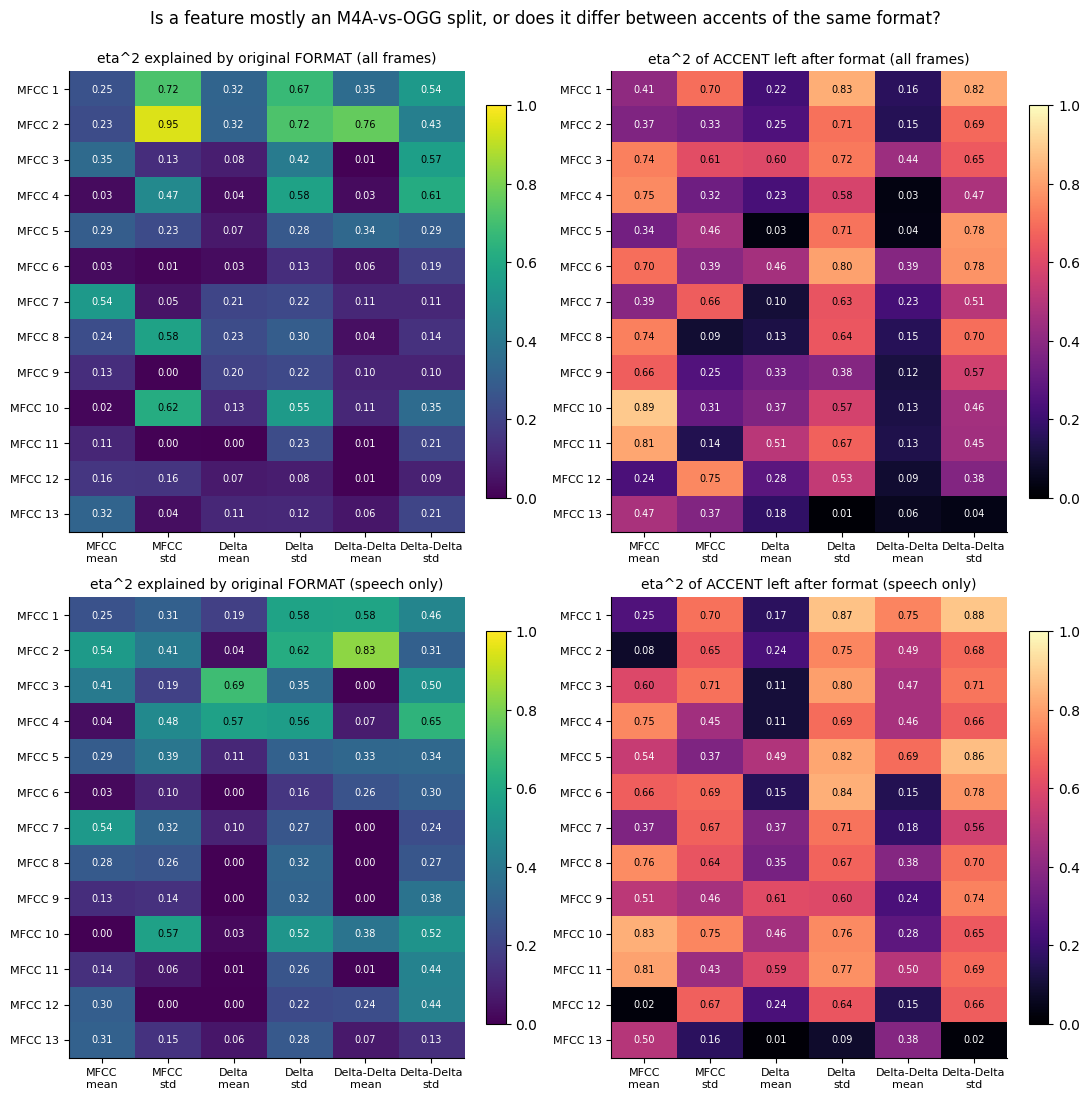

Features with eta^2(format) >= 0.5 (speech only): 14 of 78
Of these, how many keep eta^2(accent | format) >= 0.3: 11


,label,eta2_format_all,eta2_format_speech,eta2_accent_given_format_speech
2,MFCC 2 mean,0.23,0.54,0.08
12,MFCC 7 mean,0.54,0.54,0.37
19,MFCC 10 std,0.62,0.57,0.75
27,Delta MFCC 1 std,0.67,0.58,0.87
29,Delta MFCC 2 std,0.72,0.62,0.75
30,Delta MFCC 3 mean,0.08,0.69,0.11
32,Delta MFCC 4 mean,0.04,0.57,0.11
33,Delta MFCC 4 std,0.58,0.56,0.69
45,Delta MFCC 10 std,0.55,0.52,0.76
52,Delta-Delta MFCC 1 mean,0.35,0.58,0.75


In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for r, tag in enumerate(("all", "speech")):
    i1 = fp.coef_heatmap(axes[r, 0], fcm, f"eta2_format_{tag}", f"eta^2 explained by original FORMAT ({'all frames' if tag == 'all' else 'speech only'})")
    i2 = fp.coef_heatmap(axes[r, 1], fcm, f"eta2_accent_given_format_{tag}", f"eta^2 of ACCENT left after format ({'all frames' if tag == 'all' else 'speech only'})", cmap="magma")
    fig.colorbar(i1, ax=axes[r, 0], fraction=0.045); fig.colorbar(i2, ax=axes[r, 1], fraction=0.045)
fig.suptitle("Is a feature mostly an M4A-vs-OGG split, or does it differ between accents of the same format?", y=0.995)
fig.tight_layout(); save(fig, "21_format_vs_accent_eta2.png")
print("Features with eta^2(format) >= 0.5 (speech only):", int((fmt_cmp.eta2_format_speech >= 0.5).sum()), "of", len(fmt_cmp))
print("Of these, how many keep eta^2(accent | format) >= 0.3:", int(((fmt_cmp.eta2_format_speech >= 0.5) & (fmt_cmp.eta2_accent_given_format_speech >= 0.3)).sum()))
display(fmt_cmp[fmt_cmp.eta2_format_speech >= 0.5][["label", "eta2_format_all", "eta2_format_speech", "eta2_accent_given_format_speech"]].round(2))

## F. Quality-related analysis
We relate every feature to five quality measurements from Phase 2 (speech-frame share, noise floor, clipping, level deviation, duration) plus the two flags (clipping flag, level-inconsistent flag; coded 0/1). For each pair we give two correlations:
- **Pooled** (all 28 recordings): includes differences between speakers, formats and noise floors.
- **Within accent**: each accent's own average is subtracted from both numbers first, so it only reflects variation among one speaker's own recordings. This is the fairer test of whether a feature really follows a quality measure.

All 28 recordings are kept. Saved: `quality_correlations.csv` (long format, for all frames and for speech only).

saved quality_correlations.csv (1092, 8)


saved: results/feature_analysis/figures/22_quality_correlations_all_frames.png


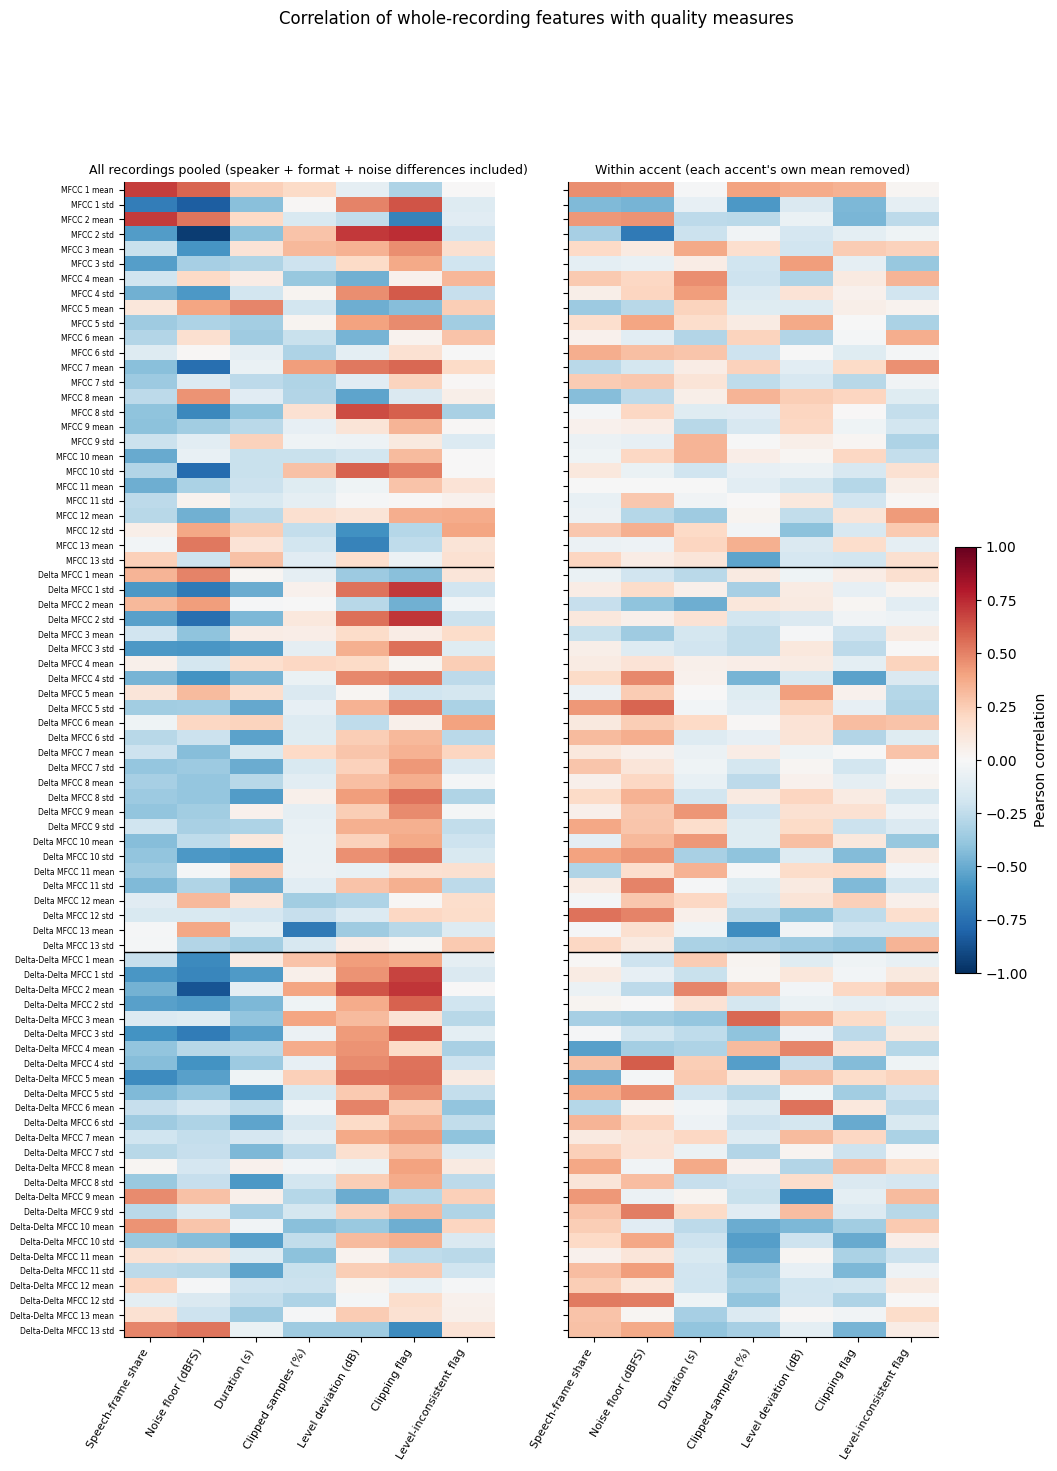

saved: results/feature_analysis/figures/23_quality_correlations_speech_only.png


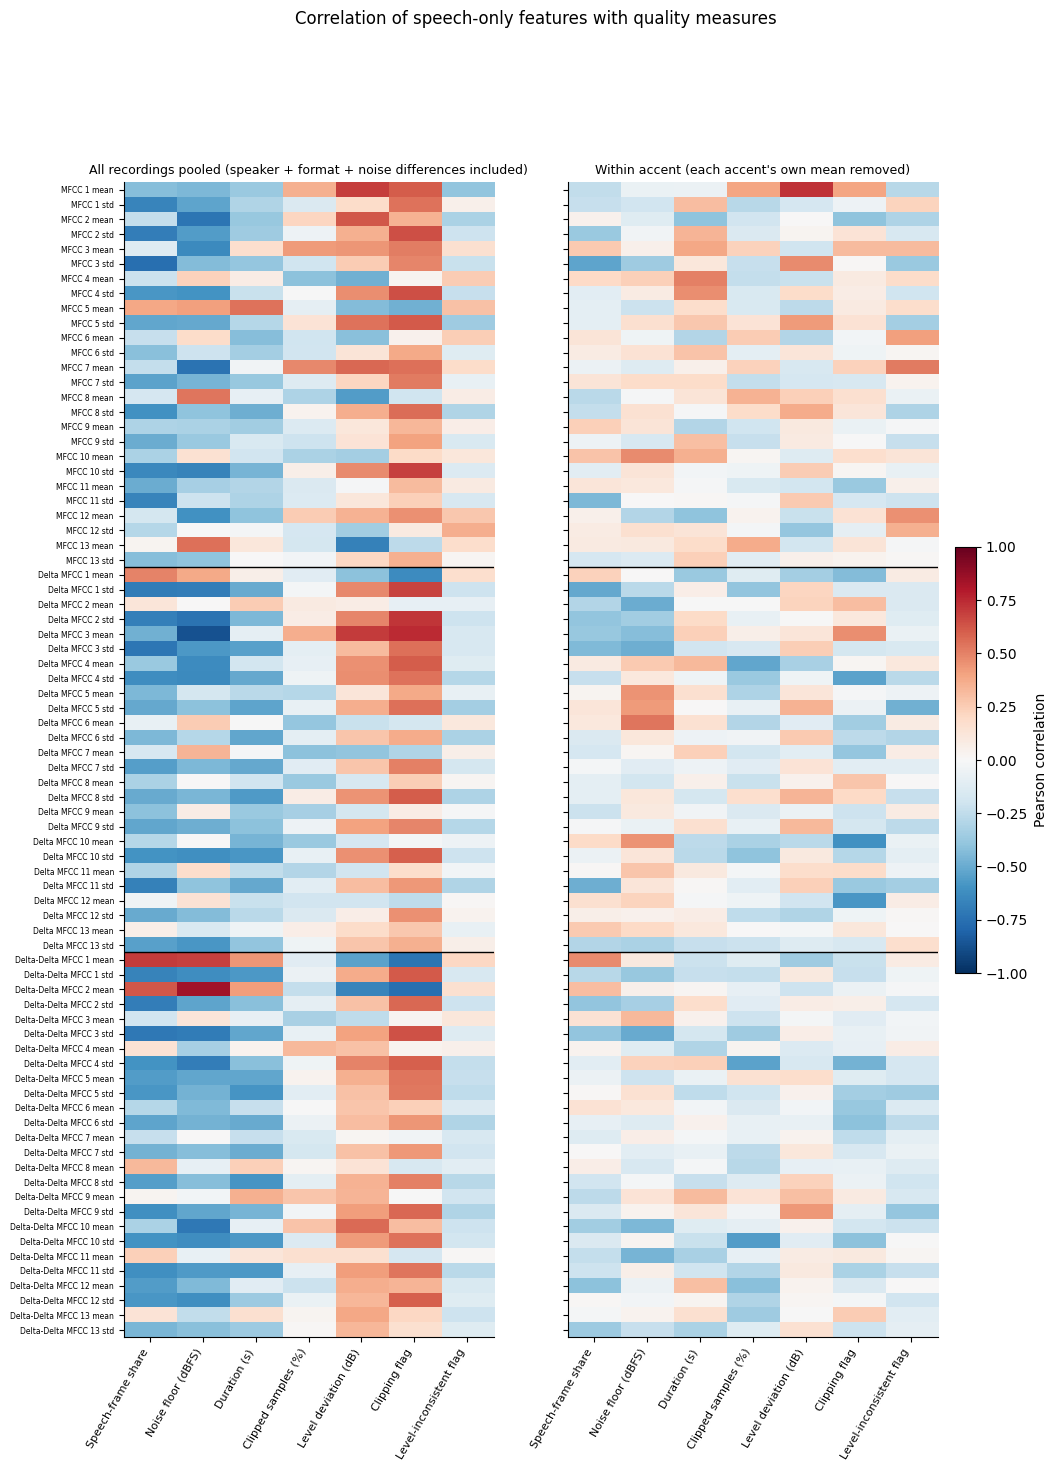

In [25]:
qcorr = fa.quality_correlations(T, Tsp, F)
qcorr.to_csv(fa.FA_DIR / "quality_correlations.csv", index=False)
print("saved quality_correlations.csv", qcorr.shape)
FIGS.append("22_quality_correlations_all_frames.png")
feature_plots.quality_corr_heatmap(qcorr, F, "all_frames", "22_quality_correlations_all_frames.png",
                                   "Correlation of whole-recording features with quality measures")
FIGS.append("23_quality_correlations_speech_only.png")
feature_plots.quality_corr_heatmap(qcorr, F, "speech_only", "23_quality_correlations_speech_only.png",
                                   "Correlation of speech-only features with quality measures")

In [26]:
key_feats = ["mfcc_01_mean", "mfcc_02_mean", "mfcc_03_mean", "mfcc_04_mean", "delta_01_std", "delta_02_std"]
view = qcorr[qcorr.feature.isin(key_feats) & qcorr.quality_metric.isin(["speech_ratio", "noise_floor_dbfs", "duration_s", "flag_clipping", "flag_level_inconsistent"])]
display(view.pivot_table(index=["label", "feature_set"], columns="quality_metric", values="pearson_within_accent").round(2))
print("(table: WITHIN-accent Pearson correlations)")

quality_metric                duration_s  flag_clipping  flag_level_inconsistent  noise_floor_dbfs  speech_ratio
label            feature_set                                                                                    
Delta MFCC 1 std all_frames         0.05          -0.08                     0.04              0.18          0.07
                 speech_only        0.06          -0.15                    -0.14             -0.27         -0.51
Delta MFCC 2 std all_frames         0.14          -0.04                    -0.05              0.05          0.10
                 speech_only        0.19           0.11                    -0.12             -0.34         -0.40
MFCC 1 mean      all_frames        -0.01           0.35                     0.02              0.45          0.47
                 speech_only       -0.06           0.40                    -0.28             -0.06         -0.25
MFCC 2 mean      all_frames        -0.26          -0.46                    -0.26              0.45          0.43
                 speech_only       -0.40          -0.40                    -0.31             -0.12          0.04
MFCC 3 mean      all_frames         0.38           0.25                     0.23              0.09          0.20
                 speech_only        0.38           0.32                     0.32              0.05          0.26
MFCC 4 mean      all_frames         0.46           0.09                     0.34              0.21          0.26
                 speech_only        0.51           0.09                     0.18              0.24          0.20

(table: WITHIN-accent Pearson correlations)


saved: results/feature_analysis/figures/24_quality_scatter_selected.png


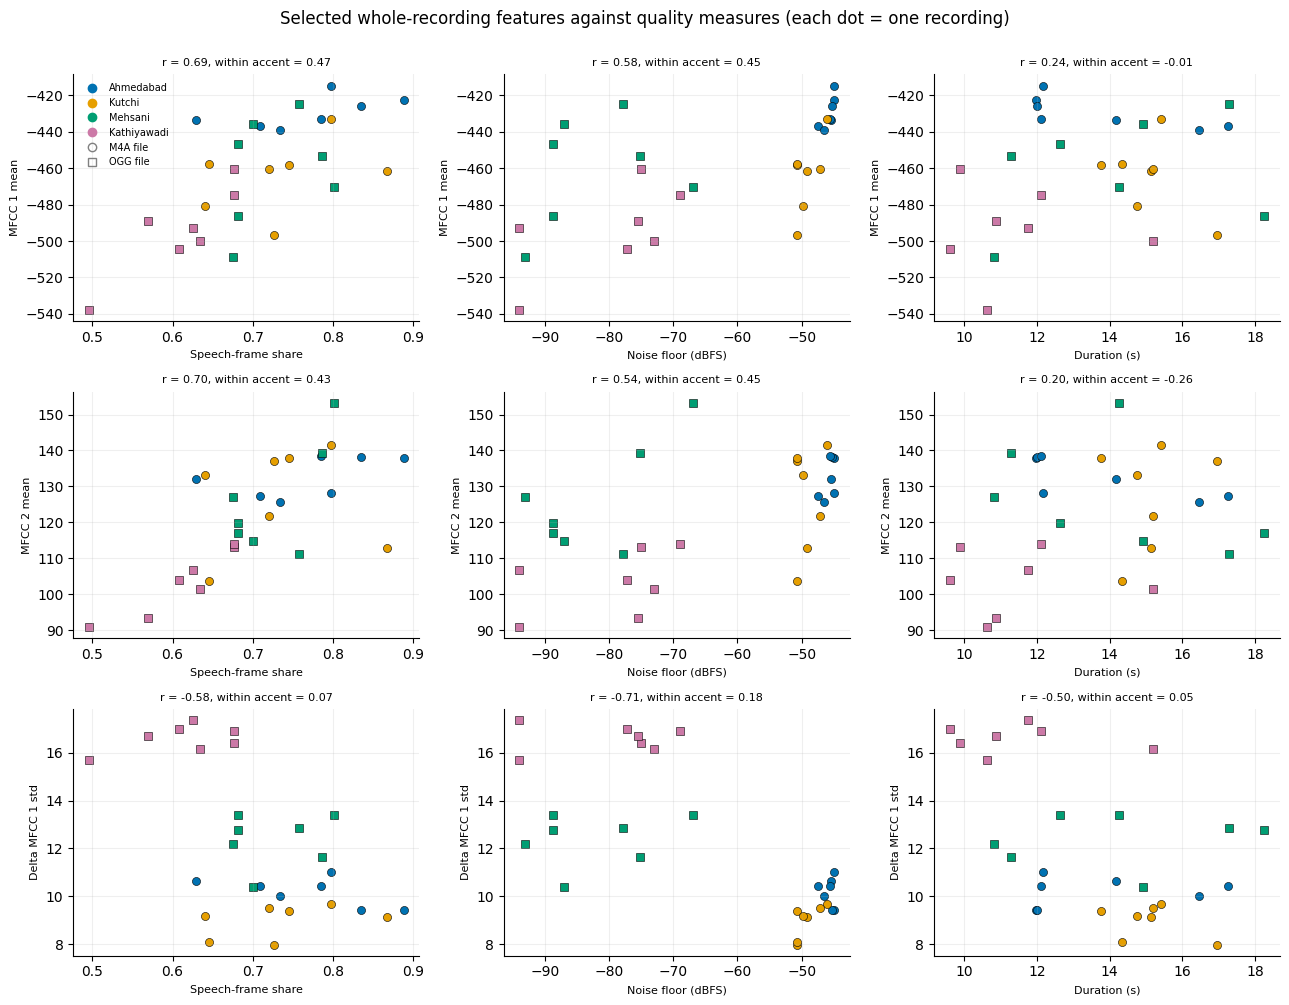

Flagged recordings kept in every analysis: 11 of 28


,flag_clipping,flag_level_inconsistent
accent,,
Ahmedabad,0,0
Kutchi,0,1
Mehsani,4,0
Kathiyawadi,6,0


In [27]:
feats_show = ["mfcc_01_mean", "mfcc_02_mean", "delta_01_std"]
qs = ["speech_ratio", "noise_floor_dbfs", "duration_s"]
fig, axes = plt.subplots(len(feats_show), len(qs), figsize=(13, 10))
for i, f in enumerate(feats_show):
    for j, q in enumerate(qs):
        ax = axes[i, j]; x, y = T[q].to_numpy(), T[f].to_numpy()
        for a in ACCENTS:
            for fm in FORMATS:
                m = ((T.accent == a) & (T.original_format == fm)).to_numpy()
                ax.scatter(x[m], y[m], color=COLORS[a], marker=MARKERS[fm], s=34, edgecolor="black", linewidth=0.4)
        ax.set_xlabel(fa.QUALITY_LABELS[q], fontsize=8); ax.set_ylabel(fa.feature_label(f), fontsize=8)
        ax.set_title("r = %.2f, within accent = %.2f" % (fa.corr_overall(x, y), fa.corr_within_accent(x, y, T.accent)), fontsize=8)
axes[0, 0].legend(handles=fp._legend_handles(ACCENTS, COLORS, FORMATS, MARKERS), frameon=False, fontsize=7)
fig.suptitle("Selected whole-recording features against quality measures (each dot = one recording)", y=1.0); fig.tight_layout()
save(fig, "24_quality_scatter_selected.png")
flagged = T[(T.flag_clipping == 1) | (T.flag_level_inconsistent == 1)]
print("Flagged recordings kept in every analysis:", len(flagged), "of", len(T))
display(T.groupby("accent")[["flag_clipping", "flag_level_inconsistent"]].sum().reindex(ACCENTS))

## G. Candidate feature investigation
Every feature gets a status from **fixed, a-priori screening rules** (written down in `src/feature_analysis.py` before any results were examined; descriptive only):

| Rule | Threshold |
|---|---|
| Overlap class (eta^2 of accent, speech-only) | high >= 0.60, moderate >= 0.30, otherwise *low* (**heavy overlap**) |
| Format-dominated | eta^2(format) >= 0.50 **and** eta^2(accent given format) < 0.30 |
| Quality-sensitive | within-accent correlation with speech share or noise floor >= 0.50 (speech-only version) |
| Stable after speech-only | eta^2 changes by <= 0.15 between all-frames and speech-only |
| **Candidate for follow-up** | status "separation present, investigate further" **and** stable **and** eta^2(accent given format) >= 0.50 |

*Being a candidate is not feature selection.* All 78 features stay in every table and no feature is discarded. A candidate just passed the checks that rule out the easiest explanations (format, silence/noise). Its apparent difference may still be due to the speaker, the wording or the room. Saved: `feature_analysis_summary.csv`.

In [28]:
fsum = fa.add_candidate_flag(fa.feature_summary(T, Tsp, F, qcorr, fmt_cmp))
fsum.to_csv(fa.FA_DIR / "feature_analysis_summary.csv", index=False)
print("saved feature_analysis_summary.csv", fsum.shape)
display(fsum.status.value_counts().to_frame("features"))
display(fsum.groupby("feature_group").status.value_counts().unstack(fill_value=0))
print("Candidates for follow-up:", int(fsum.candidate_for_follow_up.sum()), "of", len(fsum))

saved feature_analysis_summary.csv (78, 36)


,features
status,
"separation present, investigate further",64
heavy overlap,8
separation mostly follows format,3
"separation present, quality-sensitive",3


status,heavy overlap,separation mostly follows format,"separation present, investigate further","separation present, quality-sensitive"
feature_group,,,,
delta,4,2,19,1
delta2,3,0,22,1
mfcc,1,1,23,1


Candidates for follow-up: 30 of 78


In [29]:
cand = fsum[fsum.candidate_for_follow_up].copy()
def describe(row):
    f = row.feature
    means = ", ".join(f"{a[:3]} {Tsp.loc[Tsp.accent == a, f].mean():.1f}" for a in ACCENTS)
    return pd.Series({
        "feature": row.label,
        "observed (speech-only means per accent)": means,
        "eta2 accent (speech)": round(row.eta2_accent_speech, 2),
        "disjoint pairs": f"{row.disjoint_accent_pairs_speech}/{row.accent_pairs_speech}",
        "eta2 format": round(row.eta2_format_speech, 2),
        "eta2 accent|format": round(row.eta2_accent_given_format_speech, 2),
        "max |r| quality (within accent)": round(row.max_abs_r_quality_within_accent_speechonly, 2),
        "confounds to remember": "speaker, wording, device/room" + ("; partly format-associated" if row.format_flag == "partly format-associated" else "") + ("; link to quality across speakers" if row.quality_flag == "quality link only across speakers" else ""),
        "further investigation": "yes - needs more speakers and same-device recordings"})
cand_table = cand.apply(describe, axis=1) if len(cand) else pd.DataFrame()
cand_table.to_csv(fa.FA_DIR / "candidate_features.csv", index=False)
display(cand_table)

,feature,observed (speech-only means per accent),eta2 accent (speech),disjoint pairs,eta2 format,eta2 accent|format,max |r| quality (within accent),confounds to remember,further investigation
1,MFCC 1 std,"Ahm 66.2, Kut 73.1, Meh 71.5, Kat 92.0",0.79,3/6,0.31,0.70,0.23,"speaker, wording, device/room; partly format-a...",yes - needs more speakers and same-device reco...
4,MFCC 3 mean,"Ahm -19.6, Kut 1.2, Meh 15.9, Kat 3.0",0.76,2/6,0.41,0.60,0.26,"speaker, wording, device/room; partly format-a...",yes - needs more speakers and same-device reco...
6,MFCC 4 mean,"Ahm 3.7, Kut 27.5, Meh -8.7, Kat 26.3",0.76,4/6,0.04,0.75,0.24,"speaker, wording, device/room",yes - needs more speakers and same-device reco...
8,MFCC 5 mean,"Ahm -13.7, Kut -6.5, Meh -12.7, Kat -22.7",0.67,1/6,0.29,0.54,0.21,"speaker, wording, device/room",yes - needs more speakers and same-device reco...
10,MFCC 6 mean,"Ahm -3.2, Kut -3.9, Meh -14.6, Kat 2.6",0.67,2/6,0.03,0.66,0.13,"speaker, wording, device/room",yes - needs more speakers and same-device reco...
13,MFCC 7 std,"Ahm 14.5, Kut 15.5, Meh 15.8, Kat 23.0",0.78,2/6,0.32,0.67,0.19,"speaker, wording, device/room; partly format-a...",yes - needs more speakers and same-device reco...
14,MFCC 8 mean,"Ahm -4.6, Kut -4.5, Meh -24.3, Kat -4.8",0.83,3/6,0.28,0.76,0.27,"speaker, wording, device/room; link to quality...",yes - needs more speakers and same-device reco...
15,MFCC 8 std,"Ahm 14.6, Kut 13.2, Meh 14.2, Kat 18.8",0.73,3/6,0.26,0.64,0.24,"speaker, wording, device/room; link to quality...",yes - needs more speakers and same-device reco...
16,MFCC 9 mean,"Ahm -21.5, Kut -10.3, Meh -14.9, Kat -6.0",0.58,1/6,0.13,0.51,0.24,"speaker, wording, device/room",yes - needs more speakers and same-device reco...
18,MFCC 10 mean,"Ahm -13.4, Kut -9.6, Meh -21.3, Kat -3.3",0.83,4/6,0.00,0.83,0.47,"speaker, wording, device/room",yes - needs more speakers and same-device reco...


saved: results/feature_analysis/figures/25_candidate_features.png


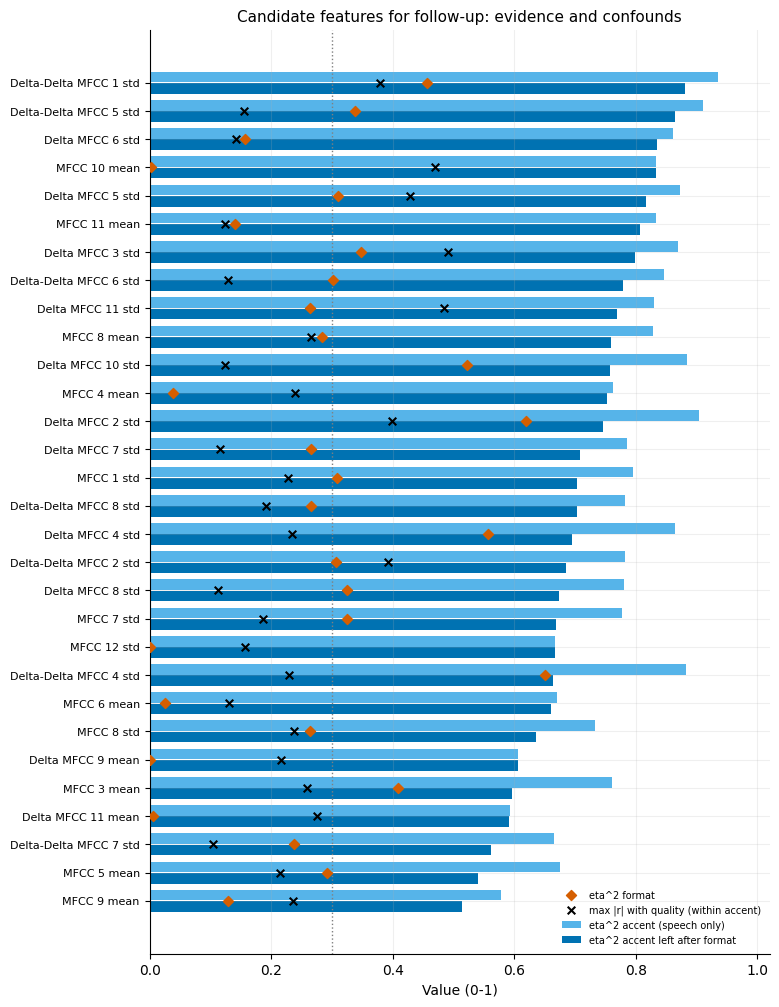

In [30]:
if len(cand):
    c = cand.sort_values("eta2_accent_given_format_speech")
    fig, ax = plt.subplots(figsize=(8, 0.34 * len(c) + 1.8))
    y = np.arange(len(c))
    ax.barh(y + 0.2, c.eta2_accent_speech, height=0.38, color="#56B4E9", label="eta^2 accent (speech only)")
    ax.barh(y - 0.2, c.eta2_accent_given_format_speech, height=0.38, color="#0072B2", label="eta^2 accent left after format")
    ax.scatter(c.eta2_format_speech, y, color="#D55E00", marker="D", s=26, zorder=3, label="eta^2 format")
    ax.scatter(c.max_abs_r_quality_within_accent_speechonly, y, color="black", marker="x", s=30, zorder=3, label="max |r| with quality (within accent)")
    ax.set_yticks(y); ax.set_yticklabels(c.label, fontsize=8); ax.set_xlim(0, 1.02); ax.set_xlabel("Value (0-1)")
    ax.axvline(fa.ETA_MODERATE, color="grey", ls=":", lw=1)
    ax.set_title("Candidate features for follow-up: evidence and confounds"); ax.legend(frameon=False, fontsize=7, loc="lower right")
    save(fig, "25_candidate_features.png")

saved: results/feature_analysis/figures/26_feature_status_overview.png


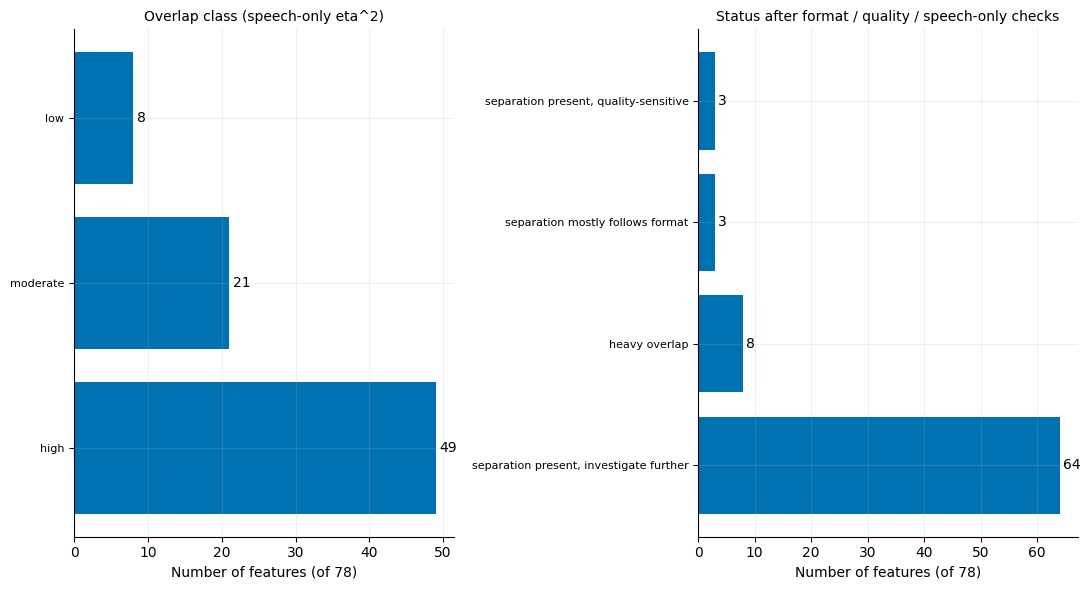

In [31]:
# status overview: all 78 features
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
sp_tab = fsum.copy()
for ax, col, title in zip(axes, ["separation_speech", "status"], ["Overlap class (speech-only eta^2)", "Status after format / quality / speech-only checks"]):
    order = fsum[col].value_counts()
    ax.barh(range(len(order)), order.values, color="#0072B2"); ax.set_yticks(range(len(order))); ax.set_yticklabels(order.index, fontsize=8)
    for i, v in enumerate(order.values): ax.text(v + 0.5, i, str(v), va="center")
    ax.set_xlabel("Number of features (of %d)" % len(fsum)); ax.set_title(title, fontsize=10)
fig.tight_layout(); save(fig, "26_feature_status_overview.png")

## H. Robustness for a future fifth accent
The analysis never names an accent. To show it copes with different category counts **without inventing any data**, the statistics are recomputed on real subsets of the existing recordings (3 accents, then 1 accent) and must run without error. Configured-but-empty accents (Surti) are listed with 0 recordings and ignored.

In [32]:
robust = []
for subset in (ACCENTS[:3], ACCENTS[:1]):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        t_sub, tsp_sub = T[T.accent.isin(subset)], Tsp[Tsp.accent.isin(subset)]
        _ = fa.accent_feature_statistics(t_sub, F, subset)
        fm_sub = fa.format_comparison(t_sub, tsp_sub, F); q_sub = fa.quality_correlations(t_sub, tsp_sub, F)
        fs_sub = fa.add_candidate_flag(fa.feature_summary(t_sub, tsp_sub, F, q_sub, fm_sub))
    robust.append((len(subset), len(t_sub), len(fs_sub)))
    print("subset of %d accent(s), %d recordings -> summary with %d features OK" % robust[-1])
print("Configured accents with no recordings (handled, not plotted):", data["configured_missing"] or "none")

subset of 3 accent(s), 21 recordings -> summary with 78 features OK


subset of 1 accent(s), 7 recordings -> summary with 78 features OK
Configured accents with no recordings (handled, not plotted): ['Surti']


## I. Validation and provenance
Final checks: all recordings accounted for, feature schema matches Phase 3, no NaN/inf, all figures exist, and no Phase 1-3 file changed.

In [33]:
HASHES_AFTER = fa.snapshot_hashes()
changed = [p for p in HASHES_BEFORE if HASHES_AFTER.get(p) != HASHES_BEFORE[p]]
new_files = [p for p in HASHES_AFTER if p not in HASHES_BEFORE]
val = list(data["checks"])
val.append(("All recordings accounted for (features == metadata == speech-only == NPZ)", len(T) == len(data["meta"]) == len(Tsp) == len(list(mf.FRAME_DIR.glob("*.npz"))), f"{len(T)} recordings"))
val.append(("Speech/non-speech alignment verified for every recording", bool(align.aligned.all()), f"{int(align.aligned.sum())}/{len(align)}"))
val.append(("No NaN/inf in speech-only or non-speech feature tables", bool(np.isfinite(Tsp[F].to_numpy(float)).all() and np.isfinite(Tns[F].to_numpy(float)).all())))
val.append(("Speech-only column names equal the Phase 3 schema", list(Tsp[F].columns) == F))
val.append(("Every speech-only recording kept at least 20 speech frames", bool((Tsp.n_speech_frames >= 20).all()), f"min {int(Tsp.n_speech_frames.min())}"))
val.append(("Robustness: subsets of 3 and 1 accents run without error", len(robust) == 2))
val.append(("Configured-but-empty accents handled", True, ", ".join(data["configured_missing"]) or "none"))
missing_figs = [n for n in FIGS if not (fa.FIG_DIR / n).is_file()]
val.append(("All generated figures exist", not missing_figs, f"{len(FIGS)} figures; missing: {missing_figs}"))
val.append(("Phase 1-3 outputs unchanged (SHA-256 before == after)", not changed, f"{len(HASHES_BEFORE)} files compared; changed: {changed}"))
expected = ["feature_analysis_summary.csv", "feature_correlations.csv", "accent_feature_statistics.csv", "format_comparison.csv", "speech_only_recording_features.csv", "quality_correlations.csv"]
val.append(("Required output files exist", all((fa.FA_DIR / f).is_file() for f in expected), ", ".join(expected)))
val = [(tuple(v) + ("",))[:3] for v in val]          # every check = (name, passed, detail)
for name, ok, detail in val:
    print("PASS" if ok else "FAIL", "-", name, ("-> " + detail) if detail else "")
all_ok = all(ok for _, ok, _ in val)
print(); print("ALL VALIDATION CHECKS PASSED" if all_ok else "SOME CHECKS FAILED")
assert all_ok

PASS - Recording IDs: Phase 1 metadata == Phase 3 features -> meta=28, features=28, only-meta=[], only-features=[]
PASS - Recording IDs: Phase 2 metrics cover every recording -> missing in Phase 2: []
PASS - Recording IDs are unique 
PASS - 'accent' agrees between Phase 1 and Phase 3 
PASS - 'speaker_id' agrees between Phase 1 and Phase 3 
PASS - 'region' agrees between Phase 1 and Phase 3 
PASS - 'original_format' agrees between Phase 1 and Phase 3 
PASS - Phase 3 feature columns match mfcc_feature_columns.json exactly (names and order) -> 78 columns
PASS - Phase 3 feature columns match the schema generated by mfcc_features.py 
PASS - Extraction parameters in schema equal mfcc_features.PARAMS 
PASS - No metadata column is listed as an acoustic feature 
PASS - No NaN/inf in the acoustic feature matrix -> 0 bad values
PASS - A frame-level NPZ exists for every recording 
PASS - 'flag_clipping' agrees between Phase 2 and Phase 3 
PASS - 'flag_level_inconsistent' agrees between Phase 2 and

In [34]:
lines = ["Phase 4 - Feature analysis validation summary", "=" * 48, "",
         f"Recordings analysed : {len(T)}", f"Accents found       : {', '.join(ACCENTS)}",
         f"Configured, no data : {', '.join(data['configured_missing']) or 'none'}", f"Original formats    : {', '.join(FORMATS)}",
         f"Acoustic features   : {len(F)}", "",
         f"Speech frames kept  : {int(Tsp.n_speech_frames.sum())} of {int(Tsp.n_frames_total.sum())} ({100 * Tsp.n_speech_frames.sum() / Tsp.n_frames_total.sum():.1f}%)",
         f"Alignment verified  : {int(align.aligned.sum())}/{len(align)} (best lag 0 frames: {int((align.best_lag_frames == 0).sum())}, +/-1 frame: {int((align.best_lag_frames.abs() == 1).sum())})",
         f"Figures created     : {len(FIGS)}", f"Files in results/feature_analysis (before this summary): {len([q for q in fa.FA_DIR.rglob('*') if q.is_file()])}", "", "Checks:"]
lines += [f"  [{'PASS' if ok else 'FAIL'}] {n}" + (f" -> {d}" if d else "") for n, ok, d in val]
lines += ["", "OVERALL: " + ("ALL CHECKS PASSED" if all_ok else "SOME CHECKS FAILED")]
(fa.FA_DIR / "validation_summary.txt").write_text(chr(10).join(lines) + chr(10), encoding="utf-8")
print(chr(10).join(lines))

Phase 4 - Feature analysis validation summary

Recordings analysed : 28
Accents found       : Ahmedabad, Kutchi, Mehsani, Kathiyawadi
Configured, no data : Surti
Original formats    : M4A, OGG
Acoustic features   : 78

Speech frames kept  : 27211 of 38127 (71.4%)
Alignment verified  : 28/28 (best lag 0 frames: 26, +/-1 frame: 2)
Figures created     : 26
Files in results/feature_analysis (before this summary): 35

Checks:
  [PASS] Recording IDs: Phase 1 metadata == Phase 3 features -> meta=28, features=28, only-meta=[], only-features=[]
  [PASS] Recording IDs: Phase 2 metrics cover every recording -> missing in Phase 2: []
  [PASS] Recording IDs are unique
  [PASS] 'accent' agrees between Phase 1 and Phase 3
  [PASS] 'speaker_id' agrees between Phase 1 and Phase 3
  [PASS] 'region' agrees between Phase 1 and Phase 3
  [PASS] 'original_format' agrees between Phase 1 and Phase 3
  [PASS] Phase 3 feature columns match mfcc_feature_columns.json exactly (names and order) -> 78 columns
  [PAS

## J. Observations, limitations and what comes next

**Observations (descriptive; numbers come from the tables above and the CSV files)**
- **Silence and noise were shaping the first coefficients.** For the whole-recording means, MFCC 1 and MFCC 2 move with the speech-frame share (r = 0.69 and 0.70 pooled; 0.47 and 0.43 within accent). On speech frames only, the MFCC 2 link disappears within accent (r = 0.04) and the MFCC 1 link changes sign (r = -0.25 within accent). Mean MFCC 1 over *non-speech* frames follows the Phase 2 noise floor across recordings (r = 0.76 pooled), but hardly within one speaker's recordings (r = 0.11).
- **Format differences flip direction.** Whole-recording MFCC 1 and MFCC 2 means are lower for OGG than for M4A (OGG has more digital-silence frames), but on speech frames they are higher for OGG (MFCC 2: 161.3 vs 136.0; MFCC 1: -390.3 vs -409.6). Speech-only MFCC 2 mean becomes **format-dominated** (eta^2 format 0.54, accent left after format 0.08).
- **Format is not the whole story.** Several features differ between accents of the *same* format (for example MFCC 4, 8, 10 and 11 means have eta^2 format <= 0.28 and eta^2 accent-given-format >= 0.51). This still cannot be called an accent effect: speaker, wording and room are untouched by this control.
- **Delta and delta-delta standard deviations separate the four speakers most strongly** (mean eta^2 of 0.75 speech-only for the 'std' features against 0.53 for the 'mean' features), but they are also the most linked to format and, across speakers, to noise floor and clipping flags. The clipping-flag correlation vanishes within a speaker (for example r = -0.15 for Delta MFCC 1 std), so it reflects which speaker/format has clipping, not an effect of clipping.
- **Heavy overlap** remains for 8 features (mostly delta and delta-delta means and MFCC 13 std).
- **Many features separate four voices** (49 of 78 have eta^2 >= 0.60 speech-only), which is what one would expect when each group is one different person. It is **not** evidence of accent separability.
- 30 of 78 features pass all candidate-screening rules. They are things to re-check with more speakers, nothing more.

**Limitations**: one speaker per accent; 28 recordings; the speech mask comes from an energy threshold (quiet speech can be missed); alignment tolerance of +/-1 frame was set after seeing two noisy recordings; screening thresholds are conventions, not tests; no significance tests; no feature was removed.

**Next (Phase 5)**: PCA and other exploratory projections, keeping both whole-recording and speech-only versions and the format/quality caveats. Phase 4 stops here: no PCA, feature selection or classification was run.